# Module 3 · Lab 3.4 — Reflection: Content Quality Pipeline
## A model critiques and revises its own output — generate → reflect → revise

**Duration:** 50 minutes | **Pattern:** Reflection (Agentic Design Pattern #10) | **Domain:** Fintech Marketing

---

## Learning Objectives

By the end of this lab, you will be able to:

1. **Implement the Reflection agentic design pattern** with cyclic graphs in LangGraph
2. **Build a hybrid evaluation system** that combines deterministic checks with LLM-based judgment
3. **Track quality score convergence** across iterations and handle the real-world cases where it doesn't converge cleanly
4. **Compare single-shot vs reflective content generation** with a proper N-trial comparison instead of n=1 vs n=1
5. **Apply production-grade safeguards** -- best-so-far tracking, early stopping on regression, and honest audit trails

---

## What is Reflection?

Reflection is an **iterative self-improvement loop** where an AI system critiques its own output and revises it based on specific feedback:

```
Generate --> Critique --> Revise --> Critique --> Revise --> ... --> Accept
```

The **idealized** promise: each iteration measurably improves quality.

The **realistic** story we will see in this lab: LLM critics are not perfectly consistent judges. Scores sometimes drift up, sometimes drift down, and occasionally regress. A naive Reflection loop can return a worse final draft than an intermediate one. This lab builds the pattern *with* the production-grade safeguards that make it actually useful.



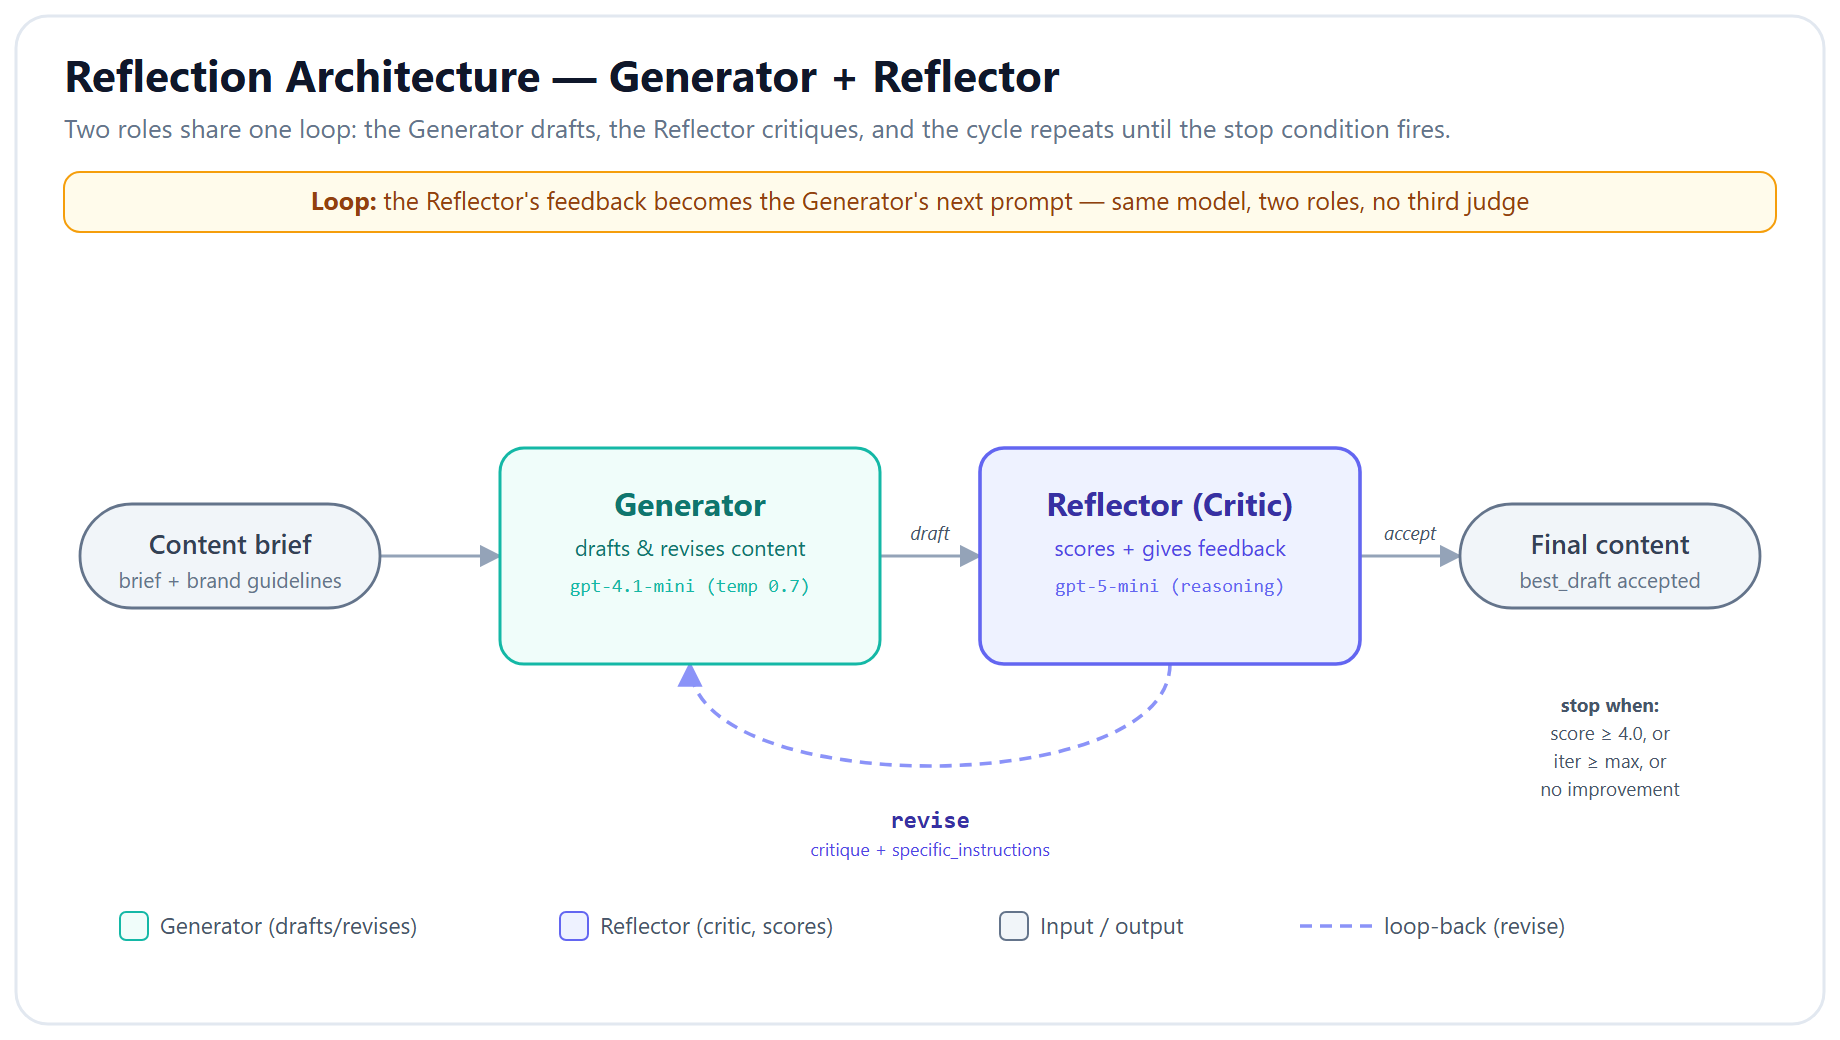

**Figure — Reflection architecture: Generator + Reflector.** Two roles share one loop: the Generator drafts from the content brief, the Reflector critiques it, and the Reflector's feedback becomes the Generator's next prompt until the stop condition fires.

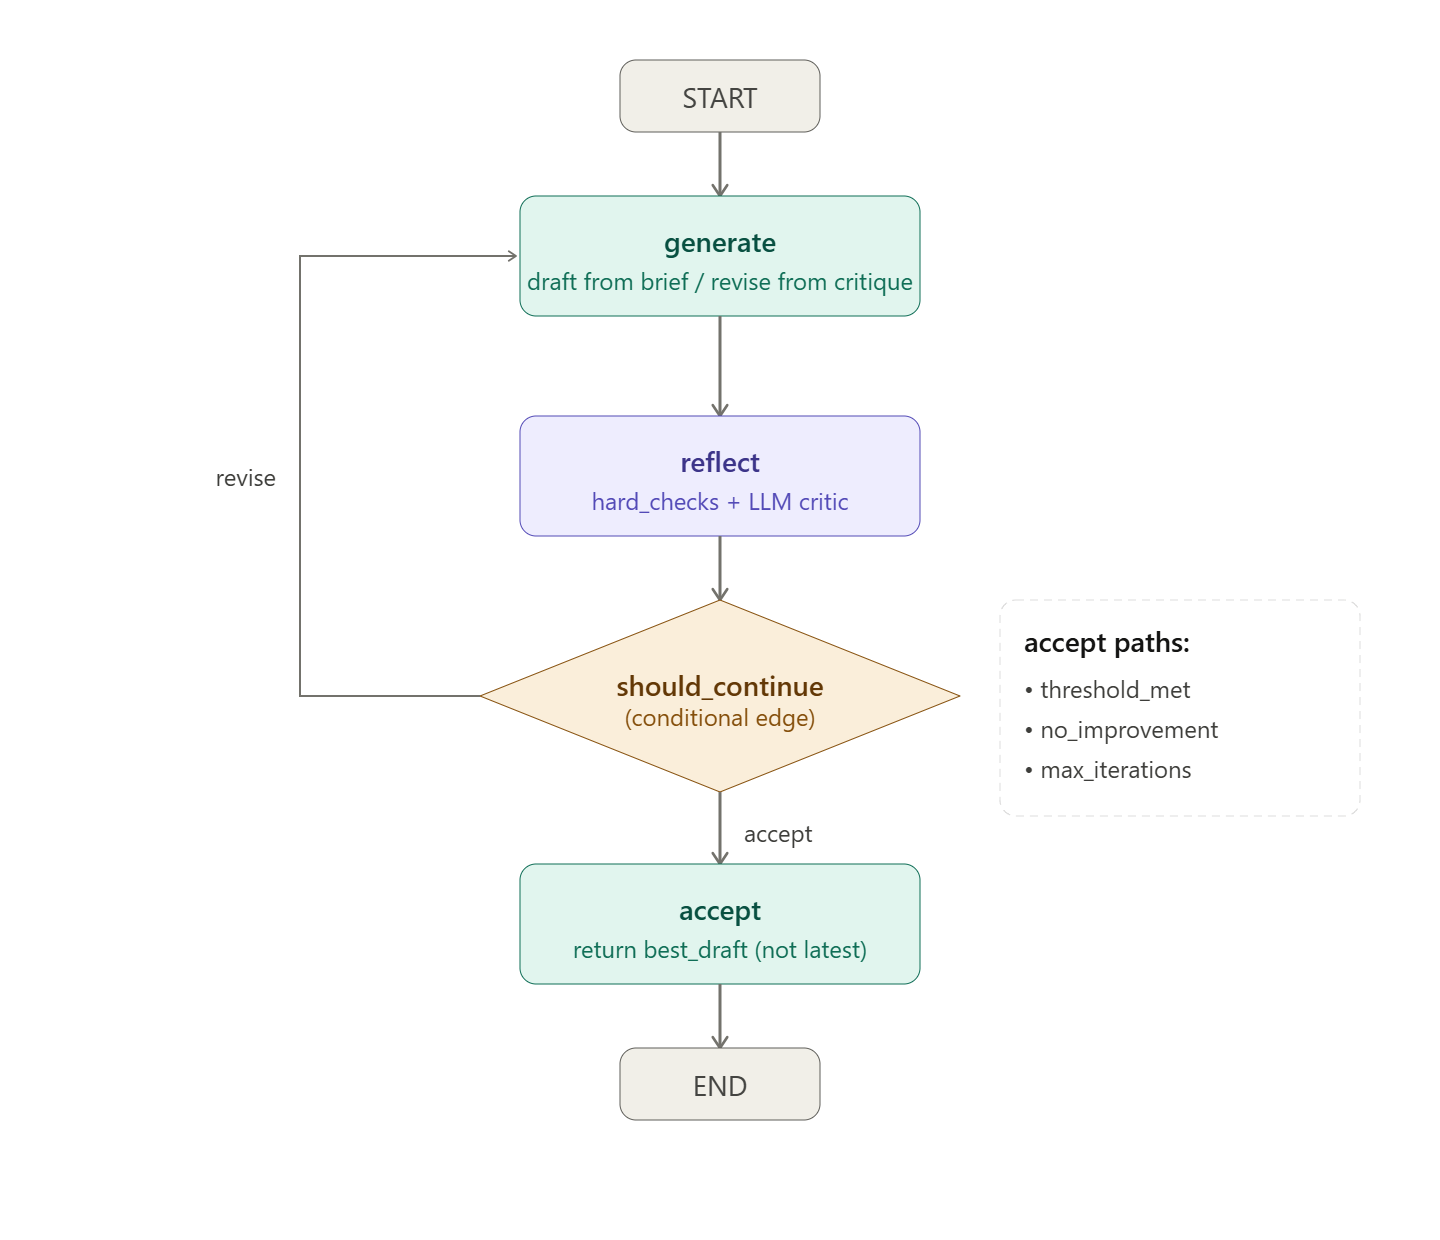

### How the Loop Works (production-grade version)

1. **Generator** produces an initial draft from a content brief
2. **Hard checks** (deterministic Python) verify binary facts: forbidden phrases, required disclaimers, word count, readability grade, structural elements
3. **LLM critic** scores only the dimensions that genuinely require judgment: brand voice, engagement, SEO quality
4. The overall score *blends* hard checks (40%) with LLM judgment (60%)
5. A **best-so-far tracker** remembers the highest-scoring draft seen across iterations
6. A **quality gate** decides whether to revise again, accept because the threshold is met, accept because we are no longer improving, or accept because max iterations is reached
7. On accept, we return the **best draft seen**, not the latest draft

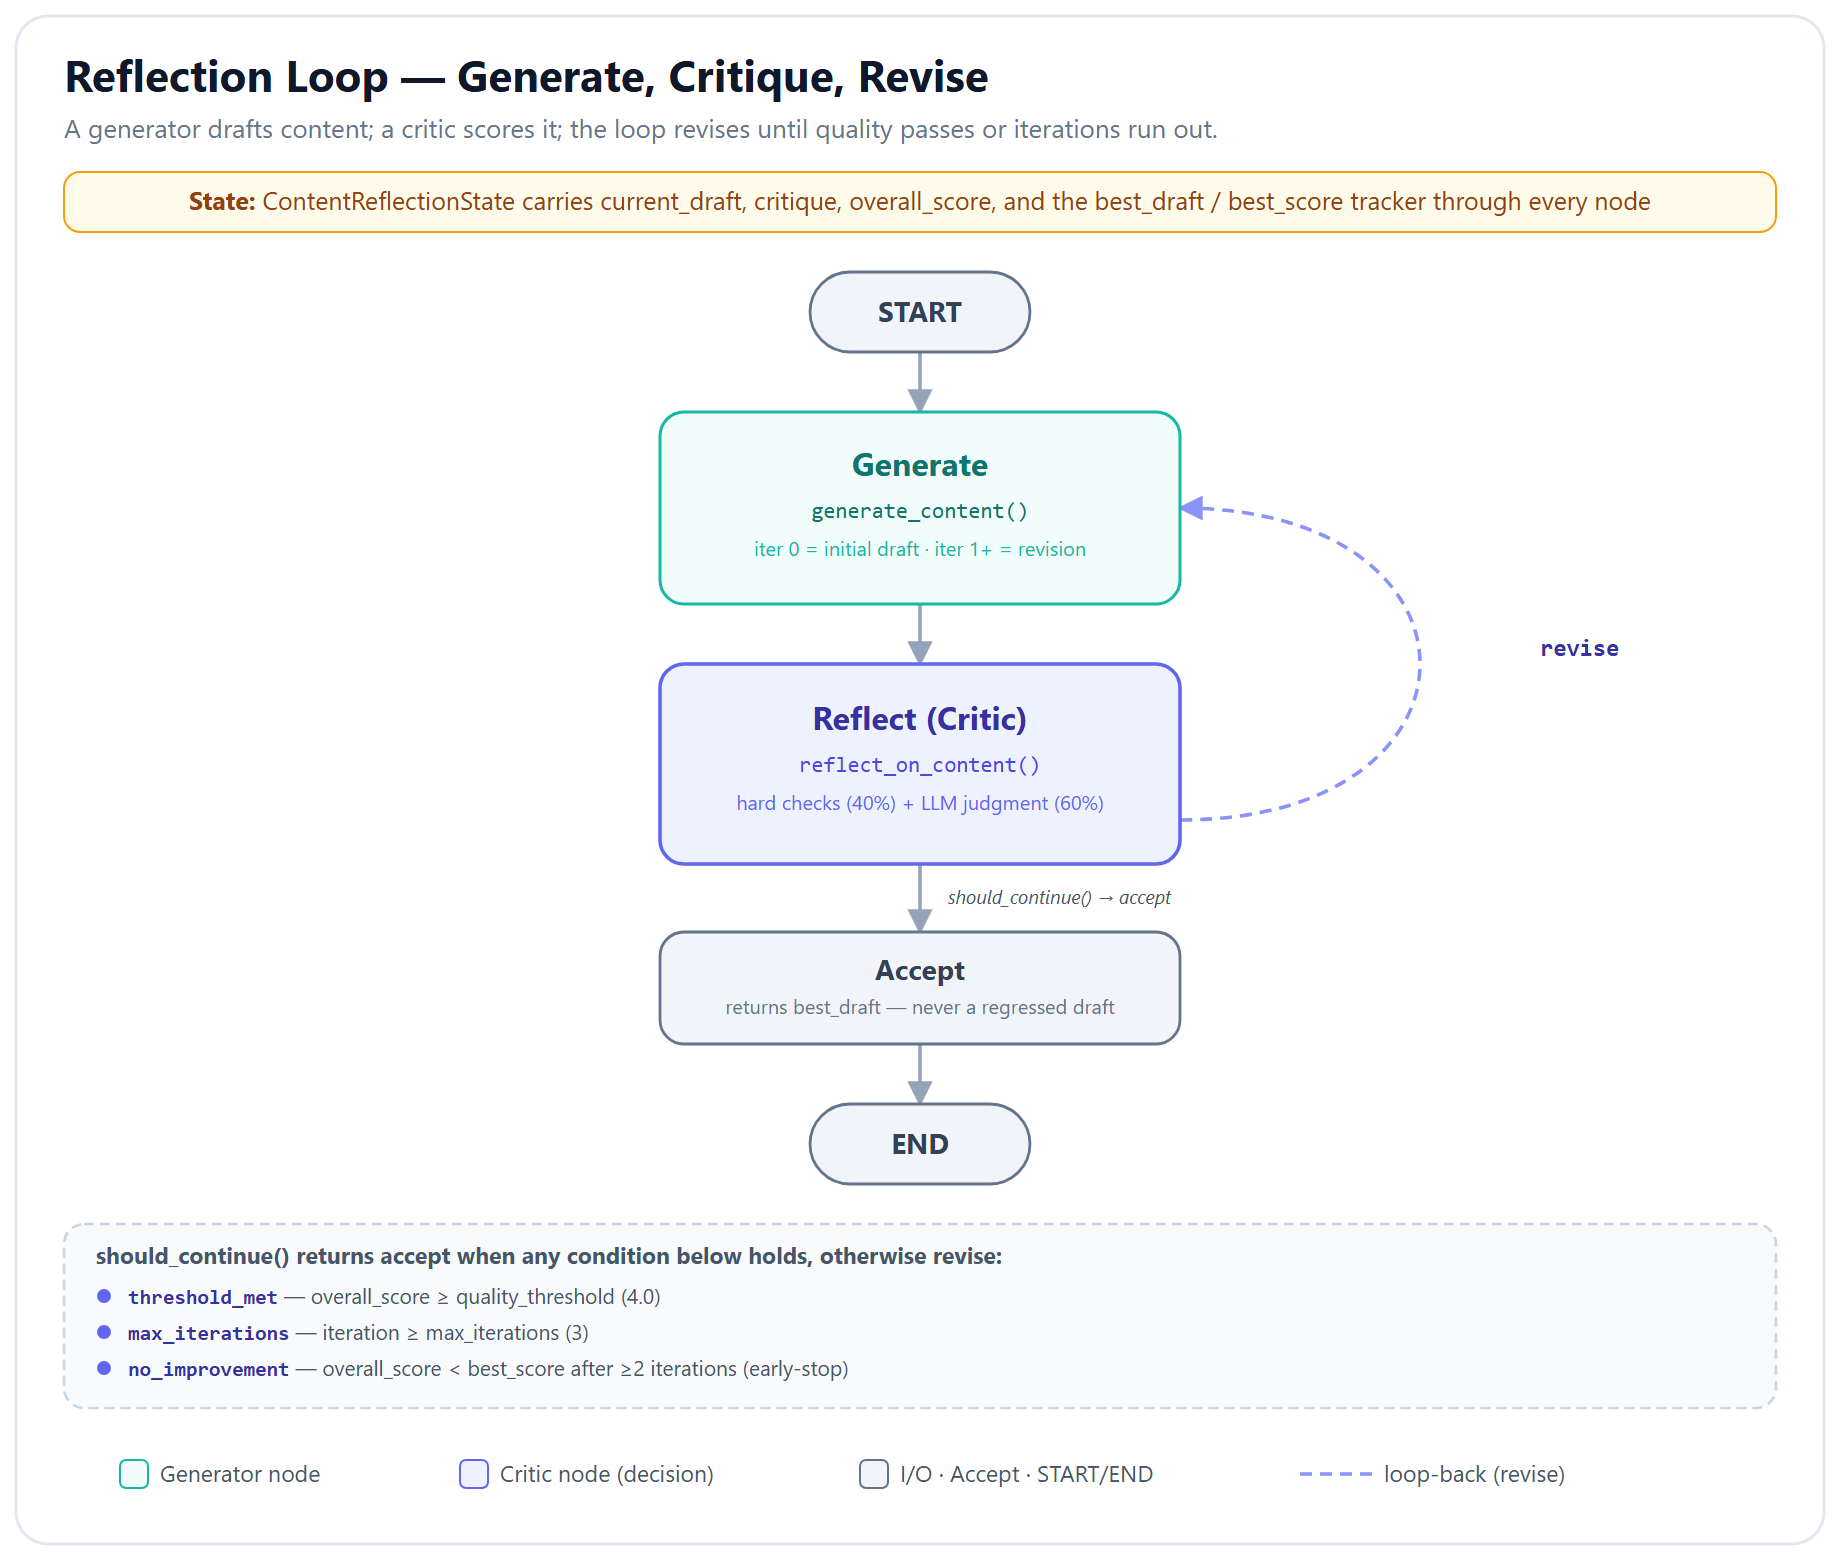

**Figure — Reflection loop: generate, critique, revise.** `generate_content()` drafts or revises, `reflect_on_content()` scores it against the blended hard-check-plus-LLM rubric, and `should_continue()` either loops back (`revise`) or exits to `accept_content()`, which returns `best_draft` — never a regressed draft.

### Reflection vs Evaluator-Optimizer

| Aspect | Evaluator-Optimizer (Lab 3.2) | Reflection (Lab 3.4) |
|--------|------------------------------|---------------------|
| **Focus** | Correctness (accuracy, compliance) | Quality (style, creativity, brand) |
| **Evaluation** | Binary pass/fail checks | Scored rubric (1-5 scale) |
| **Feedback** | "Fix this number" | "Sharpen the hook; tighten paragraph 3" |
| **Domain** | Regulated content (banking) | Creative content (marketing) |
| **Convergence** | Must reach 100% accuracy | Target quality threshold, with fallback to best-seen |
| **Graph Structure** | Linear with conditional retry | Cyclic generate-reflect loop |

### An Honest Note Up Front

LLM critics are not calibrated judges. The same critic, scoring the same draft twice, will give different scores. This means the "overall score" you see in any single iteration has real noise in it, and a score difference of 0.15-0.20 between iterations might be signal OR might be noise. The safeguards in this lab (hard checks, best-so-far tracking, early stopping, N-trial comparison) are exactly what a production Reflection system needs to handle this reality. You will see them in action -- including the cases where they save you from shipping a regressed draft.


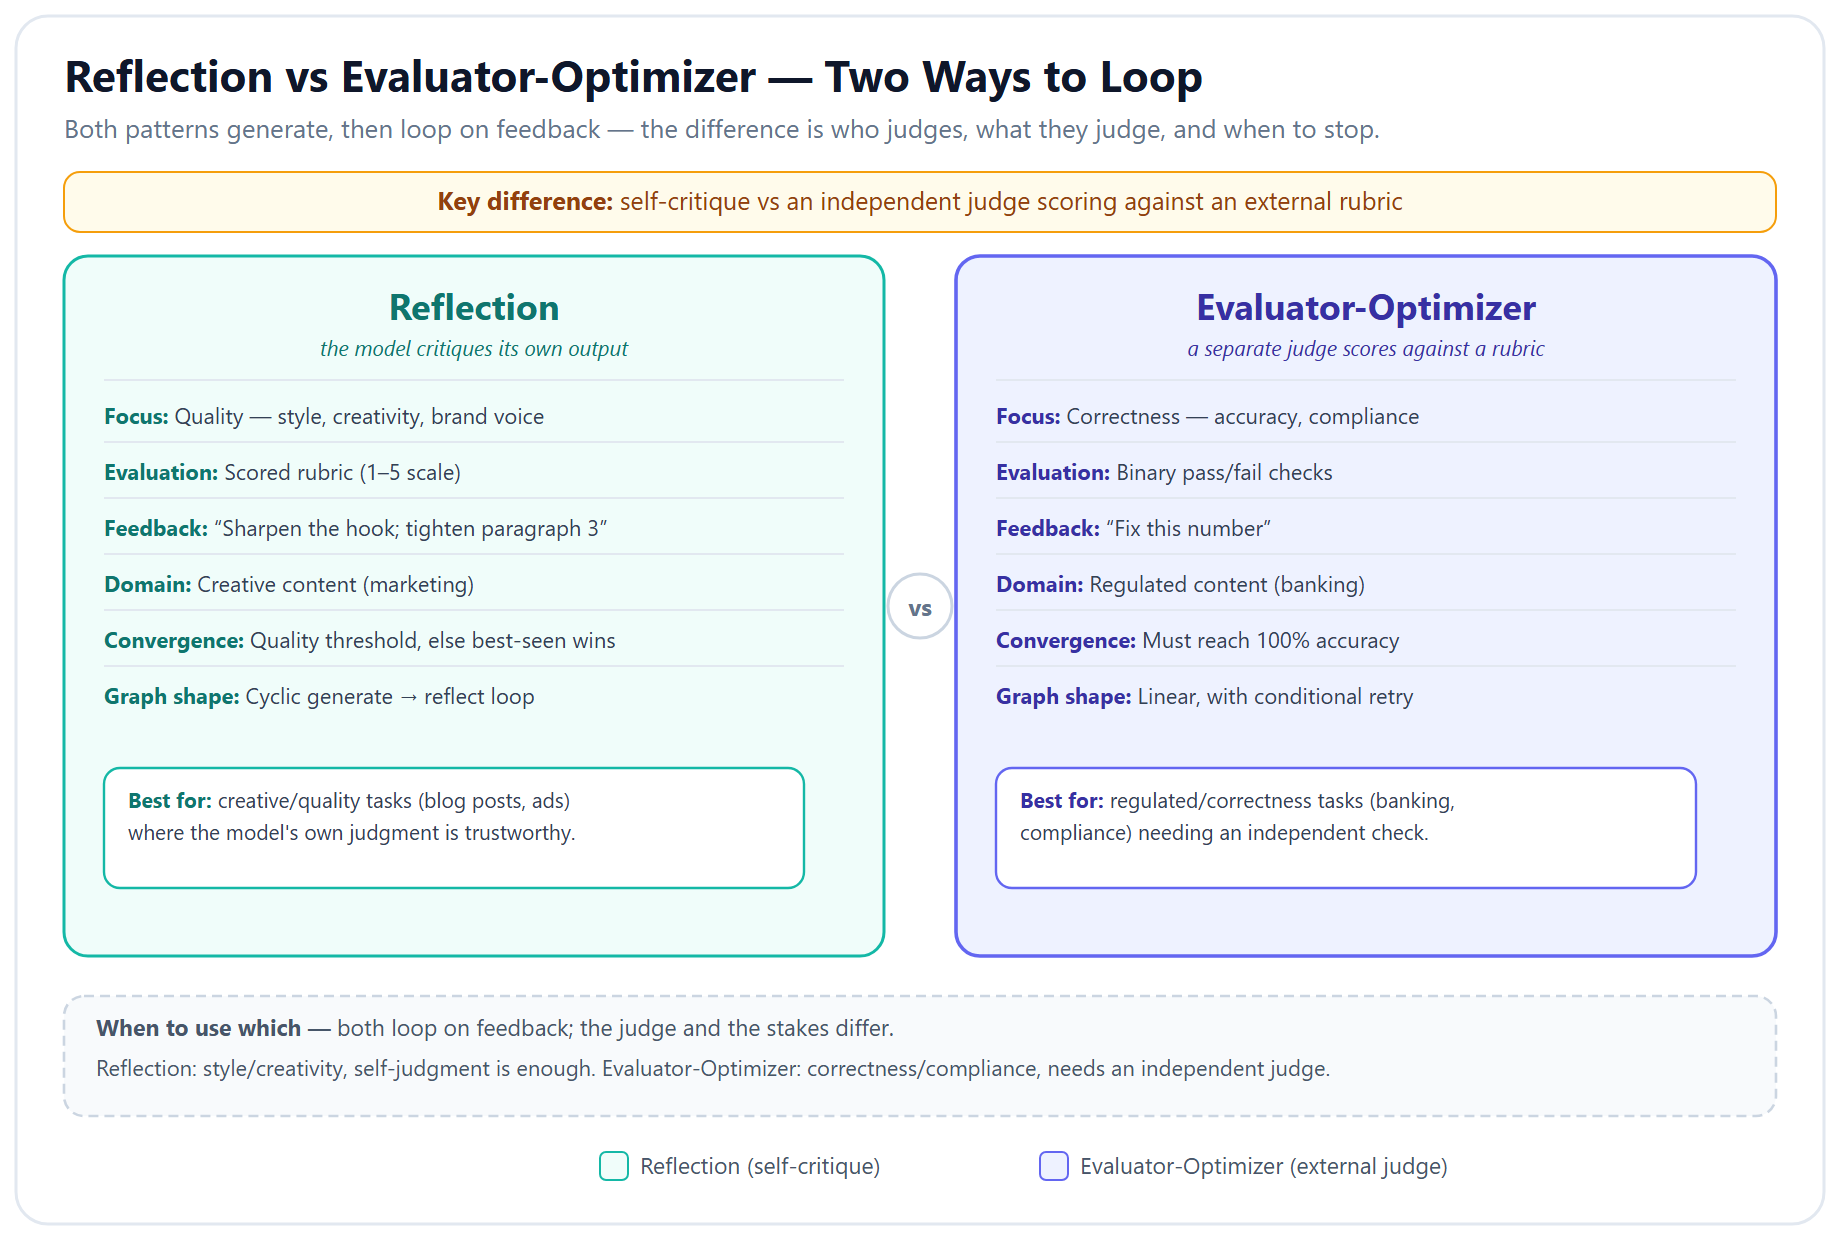

**Figure — Reflection vs Evaluator-Optimizer.** Reflection has the generator critique its own output for quality/style in a cyclic loop; Evaluator-Optimizer sends the same kind of output to a separate judge scoring correctness against a rubric in a linear-with-retry structure.

In [ ]:
# 📦 Packages this notebook needs. On the training VM they are already installed,
# so the install line below stays commented out.
# Running somewhere else (Colab, your own laptop)? Uncomment it and run this cell once.
# !pip install -qU langchain langchain-core langchain-openai langgraph pydantic textstat python-dotenv

In [ ]:
import os

def load_keys(required):
    """Load API keys from Colab Secrets (on Colab) or a local .env file (elsewhere)."""
    try:
        from google.colab import userdata          # running on Google Colab
        for key_name in required:
            try:
                os.environ[key_name] = userdata.get(key_name)
            except Exception:
                pass                                 # not set in Colab Secrets
        source = "Colab Secrets"
    except ImportError:                              # running locally / non-Colab
        try:
            from dotenv import load_dotenv, find_dotenv
            load_dotenv(find_dotenv(usecwd=True))     # searches cwd upward for a .env
        except ImportError:
            pass
        source = ".env / environment"
    print(f"🔑 Key source: {source}")
    for key_name in required:
        print(f"   {key_name:<22} {'✅' if os.environ.get(key_name) else '❌ MISSING'}")

load_keys(["OPENAI_API_KEY"])

# Core imports
from typing import TypedDict, Annotated, Literal
from pydantic import BaseModel, Field

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

from langgraph.graph import StateGraph, START, END

import operator
import json
import re
import textstat
from datetime import datetime

print("All packages installed and imported successfully.")
print(f"Timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

---

## Business Scenario: NovaCrest Financial Marketing

**Company:** NovaCrest Financial -- India's emerging fintech platform offering smart investment solutions.

**Product Launch:** "NovaCrest SmartInvest" -- an AI-powered robo-advisory service that creates personalized portfolios for retail investors.

**Challenge:** The marketing team needs high-quality content for the launch:
- Blog posts, social media copy, email campaigns
- Content must be: factually accurate, brand-aligned, SEO-optimized, and engaging
- Current manual process: writer drafts -> editor reviews -> writer revises -> editor re-reviews
- Takes **3-4 days per piece**; team needs **20 pieces in 1 week**

**Solution:** AI content pipeline with the **Reflection pattern**:
- AI generates an initial draft from a content brief
- AI critic evaluates the draft on **5 quality dimensions**
- AI reviser improves the draft based on **specific, actionable feedback**
- Bounded loop: **max 3 iterations**, exit early when quality >= **4.0/5.0**
- Expected progression: `3.2 -> 3.8 -> 4.3 -> accept`

In [ ]:
# --- Inline Data: Content Brief, Brand Guidelines & Evaluation Rubric ---

# --- 1. Content Brief ---
CONTENT_BRIEF = """CONTENT BRIEF: NovaCrest SmartInvest Launch Blog Post
============================================================

Product: NovaCrest SmartInvest
Type: Blog post (700-900 words)
Target Audience: Indian millennials and Gen-Z (ages 22-35) who are new to investing

Key Features to Highlight:
1. AI-powered portfolio construction -- analyses 10,000+ data points to build personalized portfolios
2. Start with just Rs. 500/month -- lowest entry point among Indian robo-advisors
3. SEBI-registered investment advisor (Registration No. INA000012345)
4. Auto-rebalancing -- portfolio adjusts quarterly based on market conditions
5. Goal-based investing -- set targets for travel, home, retirement
6. Real-time portfolio tracking via mobile app

Target Keywords (SEO):
- Primary: "AI investment app India", "robo-advisor India"
- Secondary: "best investment app for beginners", "automated investing India"
- Long-tail: "how to start investing with Rs 500"

Competitor Positioning:
- vs Groww/Zerodha: We offer AI-powered advice, not just a trading platform
- vs Scripbox/Kuvera: Lower minimum investment (Rs. 500 vs Rs. 1000+)
- vs international robo-advisors: Built specifically for Indian markets and regulations

Call to Action: Download NovaCrest SmartInvest app and get your free AI portfolio analysis
"""

# --- 2. Brand Guidelines ---
BRAND_GUIDELINES = """NOVACREST FINANCIAL -- BRAND VOICE GUIDELINES
============================================================

Tone: Professional yet approachable. Think "smart friend who works in finance" --
knowledgeable but never condescending. We explain complex concepts simply.

Voice Attributes:
- Confident but not arrogant
- Data-driven but not dry
- Empowering -- we help people take control of their financial future
- Inclusive -- investing is for everyone, not just the wealthy

Forbidden Words/Phrases:
- "Guaranteed returns" (regulatory violation)
- "Get rich quick" or "easy money" (misleading)
- "Beat the market" (unrealistic promise)
- "Risk-free" (no investment is risk-free)
- "Passive income" without context (oversimplifies)
- Jargon without explanation: alpha, beta, Sharpe ratio (unless defined)

Required Disclaimers (must appear in every piece):
- "NovaCrest Financial is a SEBI-registered investment advisor (Reg. No. INA000012345)"
- "Mutual fund investments are subject to market risks. Past performance is not indicative of future returns."
- "Please read all scheme-related documents carefully before investing."

Readability Target: Flesch-Kincaid Grade Level 8-10
- Short paragraphs (3-4 sentences max)
- Active voice preferred
- Sentences under 25 words on average

Formatting:
- Use subheadings every 150-200 words
- Include at least one bullet-point list
- End with a clear, single call-to-action
"""

# --- 3. Hard-check specifications (deterministic, no LLM needed) ---
FORBIDDEN_PHRASES = [
    "guaranteed returns", "get rich quick", "easy money",
    "beat the market", "risk-free", "risk free",
]

REQUIRED_DISCLAIMER_TOKENS = [
    "INA000012345",                       # SEBI registration number
    "market risk",                         # market risk disclaimer (partial match OK)
    "past performance",                    # past performance disclaimer
]

FORMAT_TARGETS = {
    "word_count_min": 700,
    "word_count_max": 900,
    "flesch_kincaid_grade_min": 8.0,
    "flesch_kincaid_grade_max": 10.0,
    "min_subheadings": 3,
    "min_bullet_lists": 1,
}


def run_hard_checks(draft: str) -> dict:
    """Deterministic validation: binary facts about the content.

    Returns a dict with per-check results and a hard_score in [0, 1].
    Much cheaper and more reliable than asking an LLM "is the disclaimer present?".
    """
    lowercase_draft = draft.lower()

    # --- Forbidden phrase check ---
    forbidden_found = [phrase for phrase in FORBIDDEN_PHRASES if phrase in lowercase_draft]
    forbidden_ok = len(forbidden_found) == 0

    # --- Required disclaimer check ---
    disclaimers_present = [token for token in REQUIRED_DISCLAIMER_TOKENS
                           if token.lower() in lowercase_draft]
    disclaimers_ok = len(disclaimers_present) == len(REQUIRED_DISCLAIMER_TOKENS)
    disclaimers_missing = [token for token in REQUIRED_DISCLAIMER_TOKENS
                           if token.lower() not in lowercase_draft]

    # --- Word count check ---
    word_count = len(re.findall(r"\b\w+\b", draft))
    word_count_ok = FORMAT_TARGETS["word_count_min"] <= word_count <= FORMAT_TARGETS["word_count_max"]

    # --- Flesch-Kincaid grade (8-10 target) ---
    try:
        flesch_kincaid_grade = textstat.flesch_kincaid_grade(draft)
    except Exception:
        flesch_kincaid_grade = 0.0
    flesch_kincaid_ok = (FORMAT_TARGETS["flesch_kincaid_grade_min"]
                         <= flesch_kincaid_grade
                         <= FORMAT_TARGETS["flesch_kincaid_grade_max"])

    # --- Structure: subheadings + bullet lists ---
    subheadings = len(re.findall(r"(?m)^\s*#{1,3}\s", draft)) + len(re.findall(r"(?m)^\s*\*\*[^*]+\*\*\s*$", draft))
    subheadings_ok = subheadings >= FORMAT_TARGETS["min_subheadings"]

    bullet_lists = len(re.findall(r"(?m)^\s*[-*]\s", draft))
    bullets_ok = bullet_lists >= FORMAT_TARGETS["min_bullet_lists"]

    # --- Aggregate hard_score in [0, 1] ---
    checks = [forbidden_ok, disclaimers_ok, word_count_ok,
              flesch_kincaid_ok, subheadings_ok, bullets_ok]
    hard_score = sum(checks) / len(checks)

    return {
        "forbidden_ok": forbidden_ok,
        "forbidden_found": forbidden_found,
        "disclaimers_ok": disclaimers_ok,
        "disclaimers_missing": disclaimers_missing,
        "word_count": word_count,
        "word_count_ok": word_count_ok,
        "flesch_kincaid_grade": round(flesch_kincaid_grade, 1),
        "fk_ok": flesch_kincaid_ok,
        "subheadings": subheadings,
        "subheadings_ok": subheadings_ok,
        "bullet_lists": bullet_lists,
        "bullets_ok": bullets_ok,
        "hard_score": round(hard_score, 2),
    }


def format_hard_check_report(hard_check_results: dict) -> str:
    """Human-readable summary of hard-check results, used as critic context."""
    lines = []
    if hard_check_results["forbidden_ok"]:
        lines.append("  OK forbidden phrases: none found")
    else:
        lines.append(f"  FAIL forbidden phrases found: {hard_check_results['forbidden_found']}")

    if hard_check_results["disclaimers_ok"]:
        lines.append("  OK all required disclaimers present")
    else:
        lines.append(f"  FAIL missing disclaimer tokens: {hard_check_results['disclaimers_missing']}")

    word_count = hard_check_results["word_count"]
    lines.append(f"  {'OK' if hard_check_results['word_count_ok'] else 'FAIL'}"
                 f" word count: {word_count} (target 700-900)")

    flesch_kincaid_grade = hard_check_results["flesch_kincaid_grade"]
    lines.append(f"  {'OK' if hard_check_results['fk_ok'] else 'FAIL'}"
                 f" Flesch-Kincaid grade: {flesch_kincaid_grade} (target 8.0-10.0)")

    lines.append(f"  {'OK' if hard_check_results['subheadings_ok'] else 'FAIL'}"
                 f" subheadings: {hard_check_results['subheadings']} (min 3)")
    lines.append(f"  {'OK' if hard_check_results['bullets_ok'] else 'FAIL'}"
                 f" bullet lists: {hard_check_results['bullet_lists']} (min 1)")

    return "\n".join(lines)


# --- 4. LLM rubric: dimensions that genuinely need human-like judgment ---
# Stripped down from 5 dimensions to 3 because accuracy and readability are
# now mostly handled by hard_checks. These 3 are things a regex can't score.
LLM_RUBRIC = {
    "brand_alignment": {
        "weight": 0.40,
        "description": (
            "Matches NovaCrest's 'smart friend in finance' tone. Professional yet "
            "approachable. Empowering and inclusive. Not salesy, pushy, or condescending."
        ),
    },
    "engagement": {
        "weight": 0.35,
        "description": (
            "Compelling hook in the first paragraph. Emotional connection with "
            "Indian millennials/Gen-Z. Relatable examples or scenarios. Clear single CTA."
        ),
    },
    "seo_quality": {
        "weight": 0.25,
        "description": (
            "Target keywords naturally integrated (not stuffed). Strong H1/H2 heading "
            "structure. Meta-description worthy opening paragraph."
        ),
    },
}

# Blend weights: hard_checks contribute 40% to overall; LLM rubric 60%.
# Hard checks catch compliance failures (critical); LLM rubric judges quality.
HARD_SCORE_WEIGHT = 0.40
LLM_SCORE_WEIGHT = 0.60


# Display the rubric structure
print("EVALUATION DESIGN")
print("=" * 70)
print(f"Hard checks (deterministic, weight {HARD_SCORE_WEIGHT:.0%}):")
print("  - Forbidden phrases (0 found = pass)")
print("  - Required disclaimers (all present = pass)")
print("  - Word count (700-900)")
print("  - Flesch-Kincaid grade (8-10)")
print("  - Subheadings (>=3), bullet lists (>=1)")
print()
print(f"LLM rubric (judgment-based, weight {LLM_SCORE_WEIGHT:.0%}):")
for dimension_name, dimension_info in LLM_RUBRIC.items():
    print(f"  - {dimension_name:<20s} weight {dimension_info['weight']:.0%}: "
          f"{dimension_info['description'][:60]}...")
print("=" * 70)
print("LLM rubric internal weights sum: "
      f"{sum(dimension_info['weight'] for dimension_info in LLM_RUBRIC.values()):.0%}")
print(f"Final score = hard_score * {HARD_SCORE_WEIGHT} + llm_score * {LLM_SCORE_WEIGHT}")

# Quick test of the hard-check function on a sample
print("\nSample hard-check on a dummy string:")
test_result = run_hard_checks("This is a short test with guaranteed returns and risk-free investments.")
print(format_hard_check_report(test_result))
print(f"  -> hard_score: {test_result['hard_score']}")


---

## State Definition

The state carries the content draft, critique feedback, dimension scores, and — critically for a production Reflection loop — a `best_draft` / `best_score` tracker so we never return a regressed version.

Key state fields:
- `current_draft`: the latest draft (may or may not be the best seen)
- `best_draft` / `best_score` / `best_iteration`: the highest-scoring draft seen so far
- `hard_check_results`: deterministic check outcomes (word count, FK grade, disclaimers, etc.)
- `llm_score`: LLM rubric weighted score (1-5)
- `overall_score`: blended score = hard × 40% + LLM × 60%
- `revision_history`: append-only audit trail via `operator.add` reducer
- `accept_reason`: why the loop stopped (`threshold_met` | `no_improvement` | `max_iterations`)


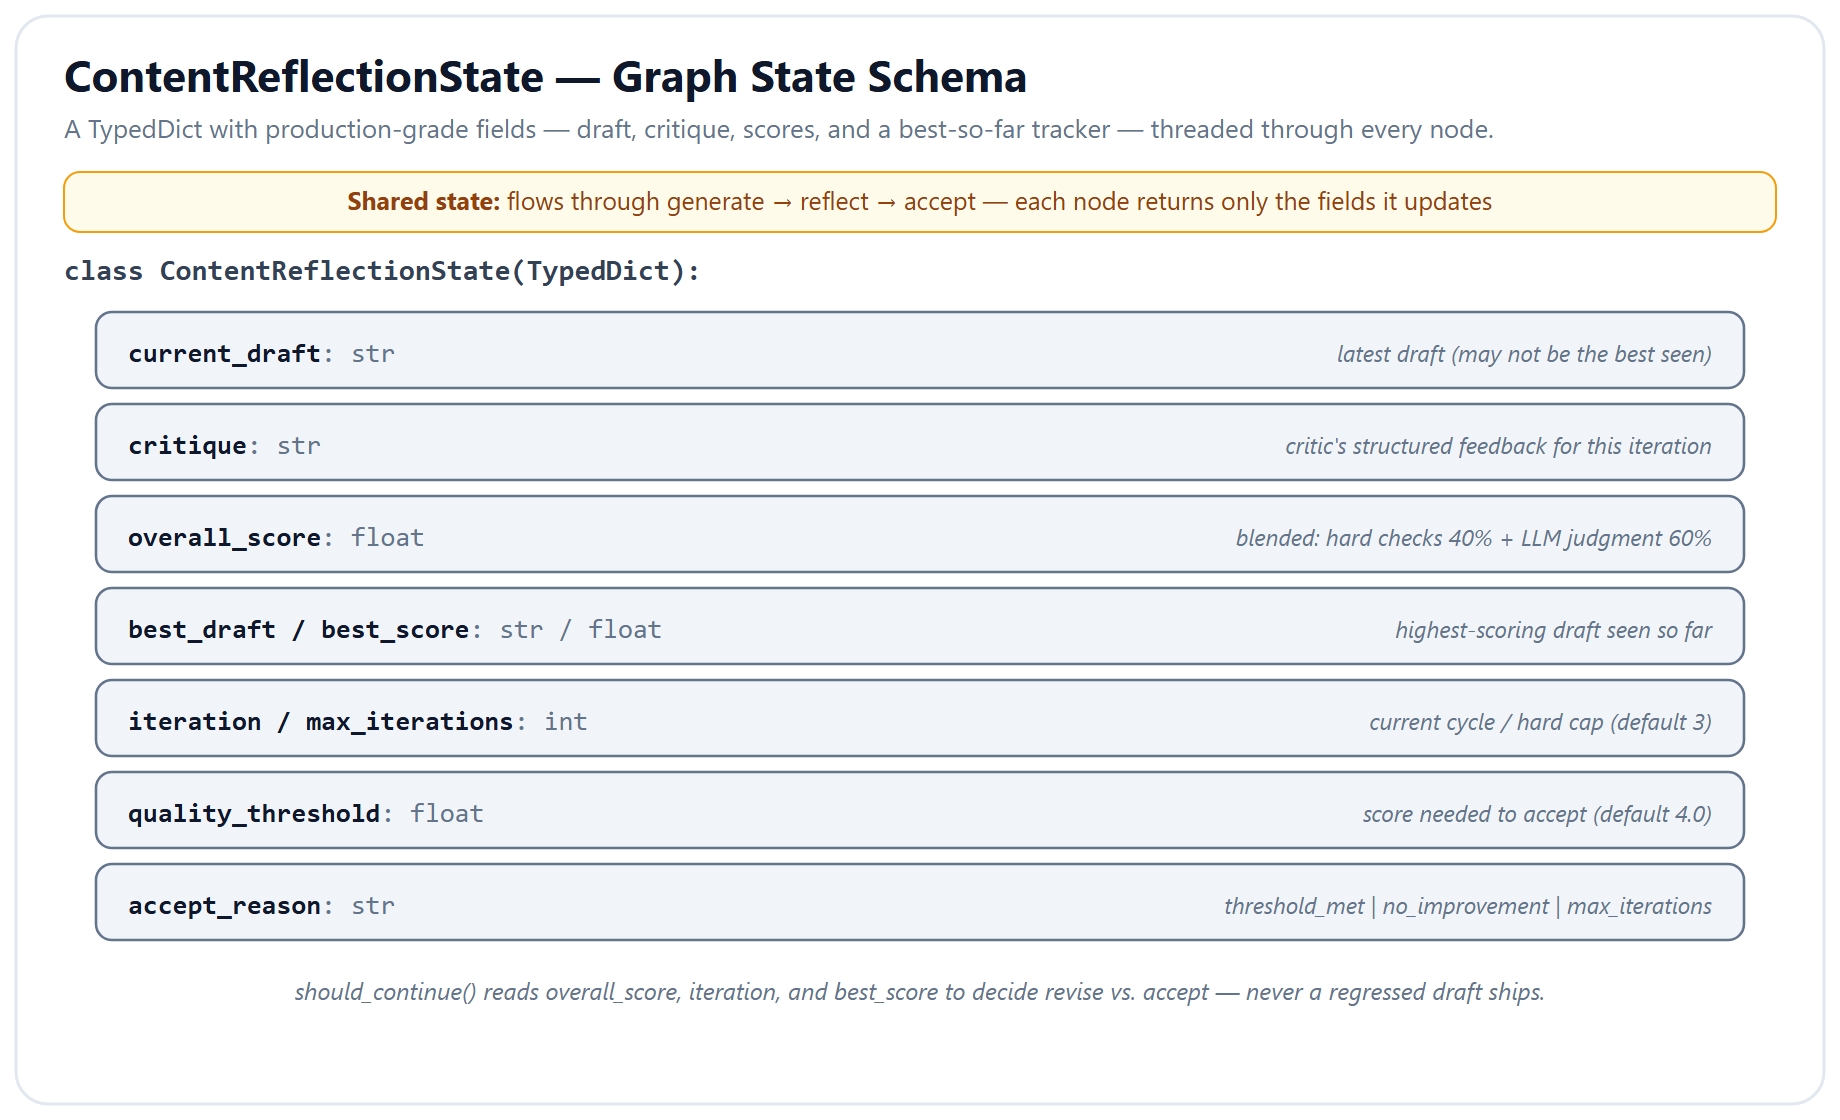

**Figure — ContentReflectionState schema.** The state's production-grade fields — `current_draft`, `critique`, `overall_score`, the `best_draft`/`best_score` tracker, `iteration`/`max_iterations`, and `accept_reason` — are what `should_continue()` reads to decide revise vs. accept.

In [ ]:
# ============================================================
# State Definition
# ============================================================

class ContentReflectionState(TypedDict):
    """State for the Reflection content quality pipeline."""

    # --- Inputs (set once at invocation) ---
    content_brief: str
    brand_guidelines: str

    # --- Working state (updated each iteration) ---
    current_draft: str
    critique: str
    specific_instructions: str
    dimension_scores: dict                      # {"brand_alignment": 4.2, ...}
    hard_check_results: dict                    # from run_hard_checks()
    llm_score: float                            # weighted LLM rubric score (1-5)
    overall_score: float                        # blended hard + LLM score (1-5)

    # --- Best-so-far tracking (prevents regression on final accept) ---
    best_draft: str                             # highest-scoring draft we have seen
    best_score: float                           # score of best_draft
    best_iteration: int                         # which iteration produced the best draft

    # --- History (append-only via add reducer) ---
    revision_history: Annotated[list, operator.add]

    # --- Control flow ---
    iteration: int
    max_iterations: int
    quality_threshold: float

    # --- Output ---
    final_content: str
    accepted: bool
    accept_reason: str                          # "threshold_met" | "no_improvement" | "max_iterations"

print("ContentReflectionState defined.")
print("\nKey production-grade fields:")
print("  - best_draft / best_score: track best seen, never return a regressed version")
print("  - hard_check_results: deterministic checks (forbidden words, disclaimers, etc.)")
print("  - accept_reason: records why the loop stopped (for audit)")


---

## Pydantic Models for Structured Critique

The critic returns structured output covering **only the three dimensions that require judgment**: brand alignment, engagement, and SEO quality. The accuracy/compliance and readability-grade dimensions live in the deterministic hard-check layer instead, because regex and `textstat` handle them better than an LLM.

The `specific_revision_instructions` field includes an explicit **non-regression rule**: do not ask for changes that would undo edits praised in `top_strength`. This is a soft mitigation for the goalpost-moving behavior where a critic asks the writer to soften, then criticizes the softening as "lacking confidence."


In [ ]:
# ============================================================
# Pydantic Models for Structured Critique
# ============================================================

from pydantic import field_validator, model_validator

ALLOWED_DIMENSIONS = {"brand_alignment", "engagement", "seo_quality"}


class DimensionScore(BaseModel):
    """Score for a single LLM-judged dimension."""
    dimension: str = Field(
        description="Must be exactly one of: brand_alignment, engagement, seo_quality"
    )
    score: float = Field(
        ge=1.0, le=5.0,
        description="Score from 1.0 (poor) to 5.0 (excellent)"
    )
    feedback: str = Field(
        description=(
            "Specific, actionable feedback for this dimension. Do NOT be vague. "
            "Example: 'The opening line is generic. Replace with a question or a "
            "specific scenario, e.g. Worried you need lakhs to start investing? Riya didn\'t.'"
        )
    )

    @field_validator("dimension")
    @classmethod
    def validate_dimension_name(cls, value: str) -> str:
        """Reject any dimension name outside the three allowed LLM-judged dimensions."""
        if value not in ALLOWED_DIMENSIONS:
            raise ValueError(
                f"dimension must be one of {sorted(ALLOWED_DIMENSIONS)}; got '{value}'"
            )
        return value


class ContentCritique(BaseModel):
    """Structured critique of marketing content across judgment-based dimensions."""
    scores: list[DimensionScore] = Field(
        description="Exactly 3 dimension scores: brand_alignment, engagement, seo_quality"
    )
    overall_assessment: str = Field(
        description="2-3 sentence overall assessment focused on tone/engagement/SEO (NOT compliance)"
    )
    top_strength: str = Field(description="The single strongest aspect of this content")
    top_weakness: str = Field(description="The single weakest aspect that most needs improvement")
    specific_revision_instructions: str = Field(
        description=(
            "3-5 concrete, non-contradictory changes for the next revision. "
            "IMPORTANT: do NOT ask for changes that would undo edits praised as strengths. "
            "Each instruction should be verifiable in the revised draft. "
            "Example: '1. Replace the generic opening with a 2-sentence micro-story about a relatable Indian millennial. "
            "2. Break the second paragraph (currently 8 sentences) into two paragraphs after sentence 4. "
            "3. Add the keyword robo-advisor India naturally in one H2 heading.'"
        )
    )

    @model_validator(mode="after")
    def validate_exactly_three_unique_dimensions(self):
        """Reject any scores list that is not exactly {brand_alignment, engagement, seo_quality}."""
        names = [dimension_score.dimension for dimension_score in self.scores]
        name_set = set(names)
        if len(names) != 3:
            raise ValueError(
                f"scores must contain exactly 3 items; got {len(names)} ({names})"
            )
        if name_set != ALLOWED_DIMENSIONS:
            missing = ALLOWED_DIMENSIONS - name_set
            extra = name_set - ALLOWED_DIMENSIONS
            raise ValueError(
                f"scores must cover exactly {sorted(ALLOWED_DIMENSIONS)}; "
                f"missing={sorted(missing)}, extra={sorted(extra)}"
            )
        if len(names) != len(name_set):
            raise ValueError(f"scores has duplicate dimension names: {names}")
        return self


print("Pydantic models defined (3 LLM-judged dimensions, strict validation):")
print("  - DimensionScore: name MUST be one of {brand_alignment, engagement, seo_quality}")
print("  - ContentCritique: scores list MUST contain exactly those 3 (no extras, no duplicates)")
print("  - Invalid critiques are rejected and automatically retried by structured_output")


---

## LLM Initialization

We use **two different models** for different roles:

| Role | Model | Why |
|------|-------|-----|
| Generator | `gpt-4.1-mini` | Creative writing needs temperature sampling |
| Critic | `gpt-5-mini` | Reasoning model for structured analytical judgment |

The critic is a reasoning model and is non-deterministic — the same draft can score differently on repeated evaluations. We compensate by putting 40% of the overall score into deterministic hard checks.


In [ ]:
# ============================================================
# LLM Initialization
# ============================================================

# Generator: creative model with temperature for varied, engaging writing
llm_generator = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0.7,
)

# Critic: reasoning model for precise analytical evaluation
# Note: gpt-5-mini is a reasoning model -- do NOT set temperature
llm_critic = ChatOpenAI(
    model="gpt-5-mini",
)

# Wrap critic with structured output for reliable JSON parsing
critic_structured = llm_critic.with_structured_output(ContentCritique)

print("LLMs initialized:")
print(f"  Generator: gpt-4.1-mini (temperature=0.7)")
print(f"  Critic:    gpt-5-mini (reasoning model, structured output)")
print(f"  Note:      critic is non-deterministic; hard_checks provide the reliable signal.")


---

## Node 1: Content Generator

This node has **two modes**:
- **Iteration 0 (initial generation):** produces a draft from the content brief. The prompt spells out the hard-check targets up front (required disclaimers, word range, FK grade, forbidden phrases) so the first draft has a shot at passing the deterministic layer.
- **Iteration 1+ (revision):** revises the current draft using the critic's feedback, with explicit **non-regression rules** in the prompt: don't remove required disclaimers, don't introduce forbidden phrases, preserve existing structure unless told otherwise, and don't undo whatever was praised in the previous iteration.


In [ ]:
# ============================================================
# Content Generator
# ============================================================

GENERATOR_SYSTEM_PROMPT = """You are an expert marketing content writer for NovaCrest Financial,
an Indian fintech company. You write blog posts that are professional yet approachable,
like a smart friend who works in finance explaining things clearly.

You always follow brand guidelines precisely and include all required disclaimers.
Your writing is SEO-optimized, engaging, and targeted at Indian millennials and Gen-Z
who are new to investing."""


def generate_content(state: ContentReflectionState) -> dict:
    """Generate or revise marketing content based on iteration.

    - Iteration 0: Generate initial draft from the content brief.
    - Iteration 1+: Revise the current draft using the critic's feedback,
      explicitly preserving what was praised and making only the requested changes.
    """
    iteration = state.get("iteration", 0)

    if iteration == 0:
        # ----- INITIAL GENERATION -----
        user_prompt = f"""Write a marketing blog post based on this content brief:

{state['content_brief']}

Brand guidelines you MUST follow:
{state['brand_guidelines']}

Requirements:
- 700-900 words (will be verified by automated word count)
- Include ALL required disclaimers VERBATIM (SEBI registration number INA000012345,
  market-risk disclaimer, past-performance disclaimer) -- these are checked by regex
- Avoid forbidden phrases: "guaranteed returns", "risk-free", "beat the market",
  "get rich quick", "easy money" -- these are checked by regex and will fail the draft
- Target Flesch-Kincaid grade 8-10 (will be measured by textstat)
- At least 3 subheadings and at least 1 bullet list
- End with a clear call-to-action

Write the complete blog post now."""
    else:
        # ----- REVISION based on critique -----
        user_prompt = f"""Revise this marketing blog post based on the editor's feedback.

CURRENT DRAFT:
---
{state['current_draft']}
---

CRITIC'S ASSESSMENT:
{state['critique']}

SPECIFIC REVISION INSTRUCTIONS (follow these precisely):
{state.get('specific_instructions', 'No specific instructions provided.')}

NON-REGRESSION RULES (critical):
- Do NOT undo changes that were previously praised (the revision should IMPROVE the draft).
- Do NOT remove required disclaimers (SEBI registration, market risk, past performance).
- Do NOT introduce forbidden phrases while rewording.
- Keep the post between 700-900 words.
- Preserve the existing subheadings and bullet lists unless the instructions explicitly
  ask you to restructure them.

BRAND GUIDELINES (for reference):
{state['brand_guidelines']}

Write the revised blog post now."""

    messages = [
        SystemMessage(content=GENERATOR_SYSTEM_PROMPT),
        HumanMessage(content=user_prompt),
    ]
    result = llm_generator.invoke(messages)

    return {
        "current_draft": result.content,
        "iteration": iteration + 1,
    }


print("generate_content node defined.")
print("  - Iteration 0: generates from brief (with hard-check targets inline)")
print("  - Iteration 1+: revises using critique + explicit non-regression rules")


---

## Node 2: Reflection / Critique Node (hybrid validation)

This is the core of the Reflection pattern with one important upgrade: **the evaluation is hybrid**.

1. **Deterministic layer** (hard checks, via `run_hard_checks()`) handles the binary facts:
   - Are the SEBI registration number and required disclaimers present? (regex)
   - Is the post between 700-900 words? (`len(re.findall(...))`)
   - Is the Flesch-Kincaid grade between 8 and 10? (`textstat`)
   - Forbidden phrases absent? Minimum subheadings and bullet list present?

2. **LLM judgment layer** (the critic) scores only the three dimensions that genuinely require human-like judgment: **brand alignment**, **engagement**, and **SEO quality**. The critic is explicitly told *not* to re-evaluate things the hard checks already handle.

3. **Best-so-far tracking**: every iteration, if the overall score beats `best_score`, we snapshot the current draft as `best_draft`. This protects against score regression — we will never return a regressed version.

Why this matters: when an LLM critic scores compliance and formatting, it can give a middling score (e.g. 3.0) to a draft that in fact has every required disclaimer and zero forbidden phrases — the critic is judging fuzzy impressions instead of the binary facts. A regex gets this right every time, for free, which is why we moved those dimensions out of the LLM's scope.


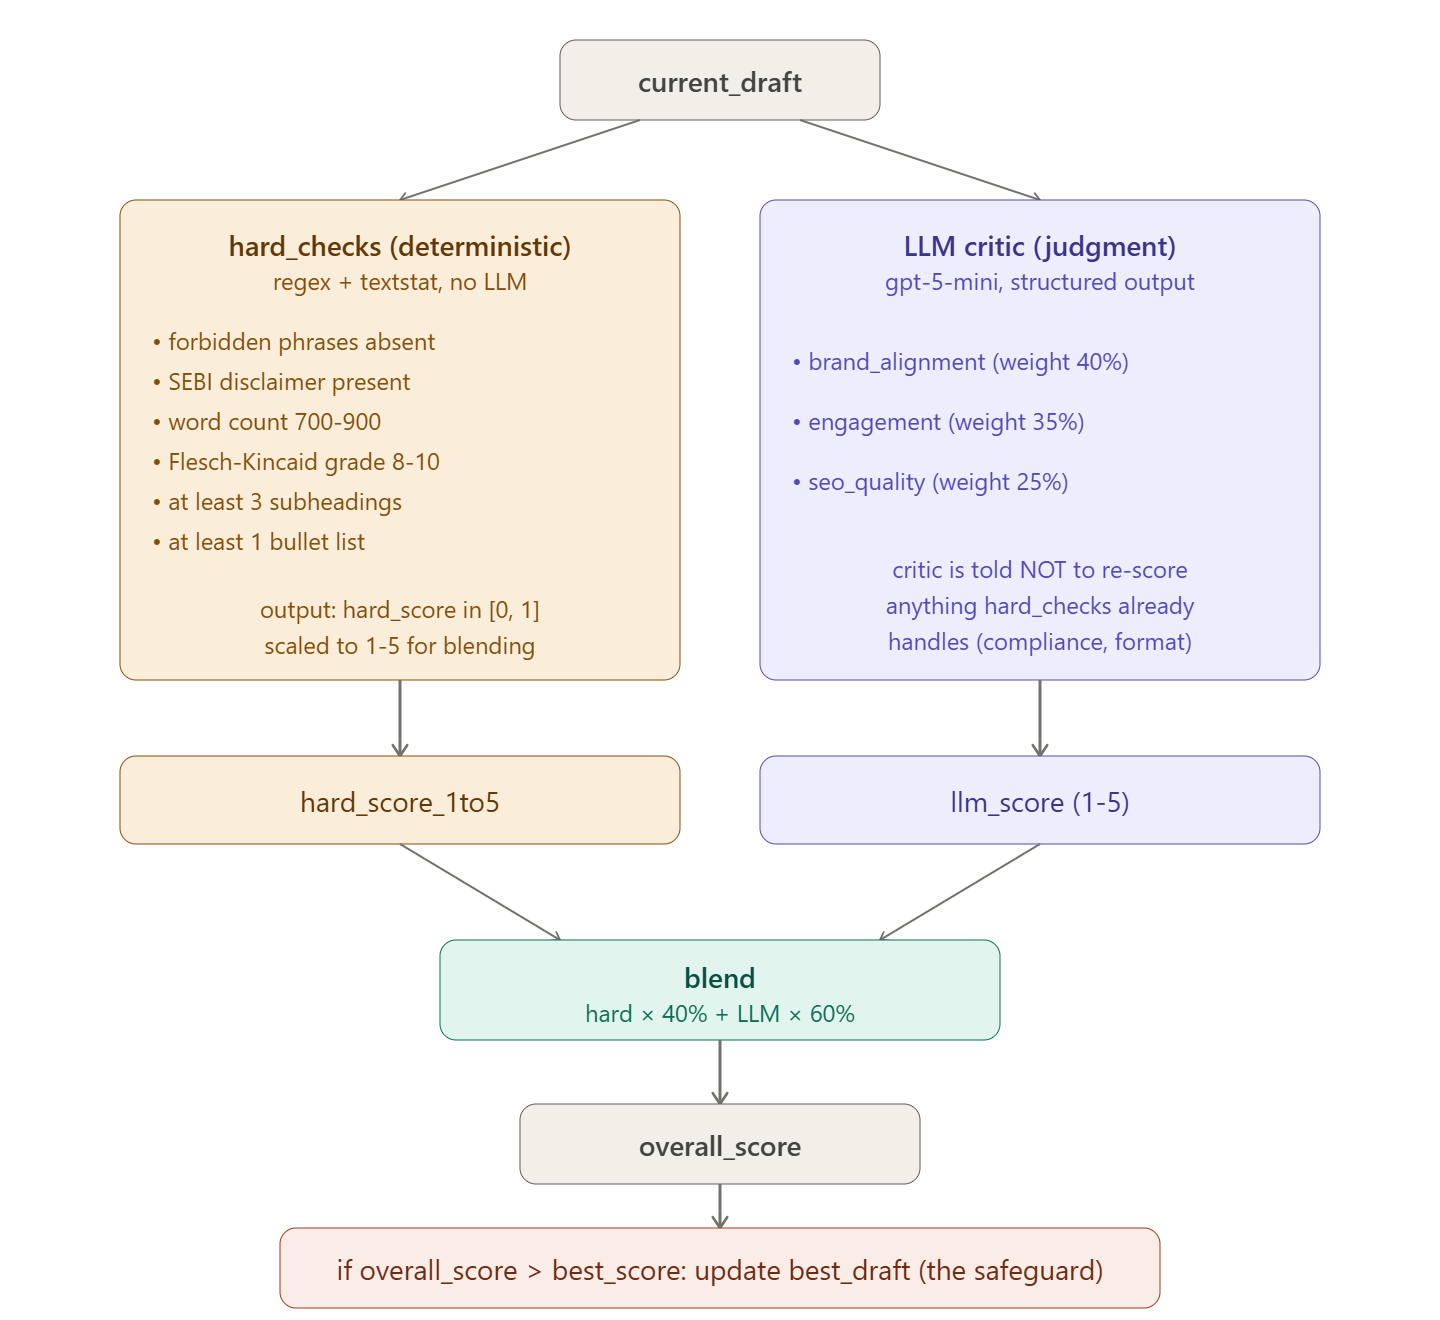

In [ ]:
# ============================================================
# Node 2 -- Reflection / Critique Node (hybrid)
# ============================================================

def reflect_on_content(state: ContentReflectionState) -> dict:
    """Hybrid evaluation: deterministic checks + LLM judgment + best-so-far tracking."""
    draft = state["current_draft"]
    iteration = state["iteration"]

    # --- 1. Deterministic hard checks (free, reliable) ---
    hard_check_results = run_hard_checks(draft)
    hard_score_1to5 = 1.0 + hard_check_results["hard_score"] * 4.0   # map [0,1] -> [1,5]
    hard_report = format_hard_check_report(hard_check_results)

    # --- 2. LLM critic on judgment dimensions only ---
    rubric_text = ""
    for dimension_name, dimension_info in LLM_RUBRIC.items():
        rubric_text += (f"\n- {dimension_name} (weight {dimension_info['weight']:.0%}): "
                        f"{dimension_info['description']}")

    critique_prompt = f"""You are a senior content editor at NovaCrest Financial.

CONTENT TO EVALUATE:
---
{draft}
---

DETERMINISTIC CHECKS (already run automatically - do NOT re-evaluate these):
{hard_report}

YOUR JOB: evaluate ONLY the 3 judgment-based dimensions below. The compliance
and formatting checks above are handled by deterministic validators. You must
NOT ask the writer to "add disclaimers" or "shorten to 700-900 words" - if
those items failed above, they will fail again until the writer fixes them,
and the hard-check report will tell them exactly what to do. Focus your
effort on things only a human editor can judge.

LLM RUBRIC (score EXACTLY these 3 dimensions -- do not add any others):
{rubric_text}

BRAND GUIDELINES (for tone and voice):
{state['brand_guidelines']}

FEEDBACK RULES:
- Be SPECIFIC and ACTIONABLE. "Improve readability" is not useful.
- Give revision instructions ONLY for dimensions you scored below 4.0.
- Do NOT ask the writer to undo changes you praise as top_strength.
- If all three dimensions are 4.0+, say so clearly - do not invent problems.

Your scores list must contain EXACTLY 3 entries, one for each of:
brand_alignment, engagement, seo_quality. Do NOT include any other dimension names."""

    # Invoke critic -- returns ContentCritique pydantic object.
    # The Pydantic validators enforce that scores is exactly 3 items named
    # brand_alignment, engagement, seo_quality. If the critic returns anything
    # else, LangChain's structured_output will auto-retry.
    critique: ContentCritique = critic_structured.invoke(critique_prompt)

    # Extract dimension scores, filtered to known keys only (belt-and-braces)
    raw_scores = {dimension_score.dimension: dimension_score.score
                  for dimension_score in critique.scores}
    dimension_scores = {dimension_name: score_value
                        for dimension_name, score_value in raw_scores.items()
                        if dimension_name in LLM_RUBRIC}

    # --- 3. Compute weighted LLM score ---
    llm_score = 0.0
    for dimension_name, dimension_info in LLM_RUBRIC.items():
        llm_score += dimension_scores.get(dimension_name, 3.0) * dimension_info["weight"]

    # --- 4. Blend hard-check score with LLM score ---
    overall_score = hard_score_1to5 * HARD_SCORE_WEIGHT + llm_score * LLM_SCORE_WEIGHT
    overall_score = round(overall_score, 2)

    # --- 5. Update best-so-far tracker ---
    prev_best = state.get("best_score", 0.0)
    beats_best = overall_score > prev_best

    # --- 6. Build history entry ---
    history_entry = {
        "iteration": iteration,
        "hard_score_1to5": round(hard_score_1to5, 2),
        "llm_score": round(llm_score, 2),
        "overall_score": overall_score,
        "dimension_scores": dimension_scores,
        "hard_checks_passing": sum([
            hard_check_results["forbidden_ok"], hard_check_results["disclaimers_ok"],
            hard_check_results["word_count_ok"], hard_check_results["fk_ok"],
            hard_check_results["subheadings_ok"], hard_check_results["bullets_ok"],
        ]),
        "hard_checks_total": 6,
        "top_strength": critique.top_strength,
        "top_weakness": critique.top_weakness,
        "draft_preview": draft[:200] + "...",
    }

    # --- 7. Assemble state update ---
    update = {
        "critique": critique.overall_assessment,
        "specific_instructions": critique.specific_revision_instructions,
        "dimension_scores": dimension_scores,
        "hard_check_results": hard_check_results,
        "llm_score": round(llm_score, 2),
        "overall_score": overall_score,
        "revision_history": [history_entry],  # appended via operator.add
    }

    if beats_best:
        update["best_draft"] = draft
        update["best_score"] = overall_score
        update["best_iteration"] = iteration

    return update


print("reflect_on_content node defined (hybrid validation).")
print("  - Runs run_hard_checks() for deterministic facts (40% of overall score)")
print("  - LLM critic scores 3 judgment dimensions (60% of overall score)")
print("  - dimension_scores is filtered to known keys (defense-in-depth vs schema leak)")
print("  - Updates best_draft / best_score when current beats the best seen")


In [ ]:
# ============================================================
# Quality Gate -- Conditional Edge
# ============================================================

def should_continue(state: ContentReflectionState) -> Literal["revise", "accept"]:
    """Quality gate: decide whether to revise or accept the content.

    Returns 'accept' if:
      - overall_score >= threshold, OR
      - iteration count has hit max_iterations, OR
      - current iteration failed to beat best_score AND iteration >= 2
        (early-stop on regression/stagnation)
    Otherwise returns 'revise'.
    """
    score = state.get("overall_score", 0.0)
    threshold = state.get("quality_threshold", 4.0)
    iteration = state.get("iteration", 0)
    max_iterations = state.get("max_iterations", 3)
    best_score = state.get("best_score", 0.0)
    best_iteration = state.get("best_iteration", 0)

    # Path 1: threshold met
    if score >= threshold:
        print(f"  GATE iter={iteration}: score {score:.2f} >= threshold {threshold:.1f} -> ACCEPT (threshold_met)")
        return "accept"

    # Path 2: max iterations reached
    if iteration >= max_iterations:
        print(f"  GATE iter={iteration}: max_iterations reached (best={best_score:.2f} at iter {best_iteration}) -> ACCEPT (max_iterations)")
        return "accept"

    # Path 3: no improvement over best (regression or stagnation after at least 2 iters)
    if iteration >= 2 and score < best_score:
        print(f"  GATE iter={iteration}: score {score:.2f} did not beat best {best_score:.2f} "
              f"(from iter {best_iteration}) -> ACCEPT (no_improvement)")
        return "accept"

    # Revise further
    print(f"  GATE iter={iteration}: score {score:.2f} < threshold {threshold:.1f}, "
          f"best={best_score:.2f}, iter {iteration}/{max_iterations} -> REVISE")
    return "revise"


print("should_continue quality gate defined.")
print("  Accept paths: threshold_met | max_iterations | no_improvement (early-stop)")
print("  Revise path:  below threshold AND still improving AND iterations remaining")


In [ ]:
# ============================================================
# Accept Node -- Finalize with the Best Draft
# ============================================================

def accept_content(state: ContentReflectionState) -> dict:
    """Finalize: return the best_draft seen and record why the loop stopped."""
    current_score = state.get("overall_score", 0.0)
    best_score = state.get("best_score", 0.0)
    best_iteration = state.get("best_iteration", 0)
    threshold = state.get("quality_threshold", 4.0)
    iteration = state.get("iteration", 0)
    max_iterations = state.get("max_iterations", 3)
    best_draft = state.get("best_draft", state.get("current_draft", ""))

    # Determine accept reason (mirrors the gate's logic)
    if best_score >= threshold:
        reason = "threshold_met"
        status_line = f"PASSED quality threshold ({best_score:.2f} >= {threshold:.1f})"
    elif iteration >= max_iterations and current_score >= best_score:
        reason = "max_iterations"
        status_line = f"ACCEPTED at max iterations (best effort: {best_score:.2f}/{threshold:.1f})"
    elif iteration >= 2 and current_score < best_score:
        reason = "no_improvement"
        status_line = (f"EARLY-STOP on regression: iter {iteration} scored {current_score:.2f}, "
                       f"did not beat best {best_score:.2f} from iter {best_iteration}")
    else:
        reason = "max_iterations"
        status_line = f"ACCEPTED (best effort: {best_score:.2f}/{threshold:.1f})"

    print(f"\n{'='*60}")
    print(f"ACCEPT: {status_line}")
    print(f"  Best score: {best_score:.2f}/5.00 (from iteration {best_iteration})")
    print(f"  Iterations run: {iteration}")
    print(f"  Returning: best_draft from iteration {best_iteration} (NOT current iteration)")
    print(f"{'='*60}")

    return {
        "final_content": best_draft,   # <-- best, not current
        "accepted": True,
        "accept_reason": reason,
    }


print("accept_content node defined.")
print("  Returns best_draft (not current_draft) - this is the key production safeguard.")


---

## Build the Reflection Graph

This is the **key teaching point** of the lab: the **cyclic graph**. The edge from `reflect` back to `generate` is what makes this a Reflection loop instead of a linear pipeline.

```
START --> generate --> reflect --+
                         ^       |
                         |       +--[revise]--> generate   (cycle)
                         |
                         +--[accept]--> accept --> END
```

The conditional edge `should_continue` routes to `accept` under three conditions:
1. `threshold_met` — current score ≥ 4.0
2. `max_iterations` — we've done 3 revisions already
3. `no_improvement` — current score didn't beat the best seen AND we have ≥ 2 iterations to compare

The third accept path is the one that prevents the naive Reflection failure mode: iteration N+1 regresses, the loop continues anyway, and the regressed version ships. With early-stop, the loop halts as soon as we see no forward progress, and the `accept` node returns `best_draft` rather than `current_draft`.


In [ ]:
# ============================================================
# Build the Reflection Graph
# ============================================================

builder = StateGraph(ContentReflectionState)

# --- Add nodes ---
builder.add_node("generate", generate_content)
builder.add_node("reflect", reflect_on_content)
builder.add_node("accept", accept_content)

# --- Add edges ---
builder.add_edge(START, "generate")          # Entry point
builder.add_edge("generate", "reflect")      # Every generation is followed by critique

# CONDITIONAL EDGE: The reflection loop
# This is what makes Reflection different from a linear pipeline.
# The 'revise' path loops BACK to 'generate', creating a cycle.
builder.add_conditional_edges(
    "reflect",
    should_continue,
    {
        "revise": "generate",   # <-- LOOP BACK: this creates the reflection cycle
        "accept": "accept",     # Exit the loop: quality is sufficient
    },
)

builder.add_edge("accept", END)              # Finalize and exit

# --- Compile ---
graph = builder.compile()

print("Reflection graph compiled successfully!")
print("\nGraph structure:")
print("  START --> generate --> reflect --[revise]--> generate  (CYCLE)")
print("                                  |")
print("                                  +--[accept]--> accept --> END")

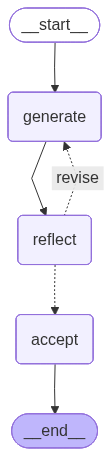

In [ ]:
# --- Visualize the Reflection Graph ---

# ============================================================
# Cell 19: Visualize the Graph
# ============================================================

from IPython.display import Image, display

try:
    graph_image_bytes = graph.get_graph().draw_mermaid_png()
    display(Image(graph_image_bytes))
except Exception as error:
    print(f"Could not render graph image: {error}")
    print("\nMermaid diagram:")
    print(graph.get_graph().draw_mermaid())

---

## Running the Reflection Pipeline

Watch the quality scores evolve across iterations.

**What to expect (honest version):**
- The overall score should *generally* trend upward but may occasionally regress between iterations — that is normal LLM-critic noise
- If iteration 3 scores lower than iteration 2, the early-stop gate will fire and we return iteration 2's draft (that is the `best_draft` safeguard earning its keep)
- Hard checks contribute 40% of the score and are deterministic — they only change when the draft changes, not because of critic drift
- The 60% LLM-judgment portion can shift by ±0.10-0.20 even between runs on the same draft

A single `graph.invoke()` call runs the pipeline once. We stream updates as they happen so you can watch each node.


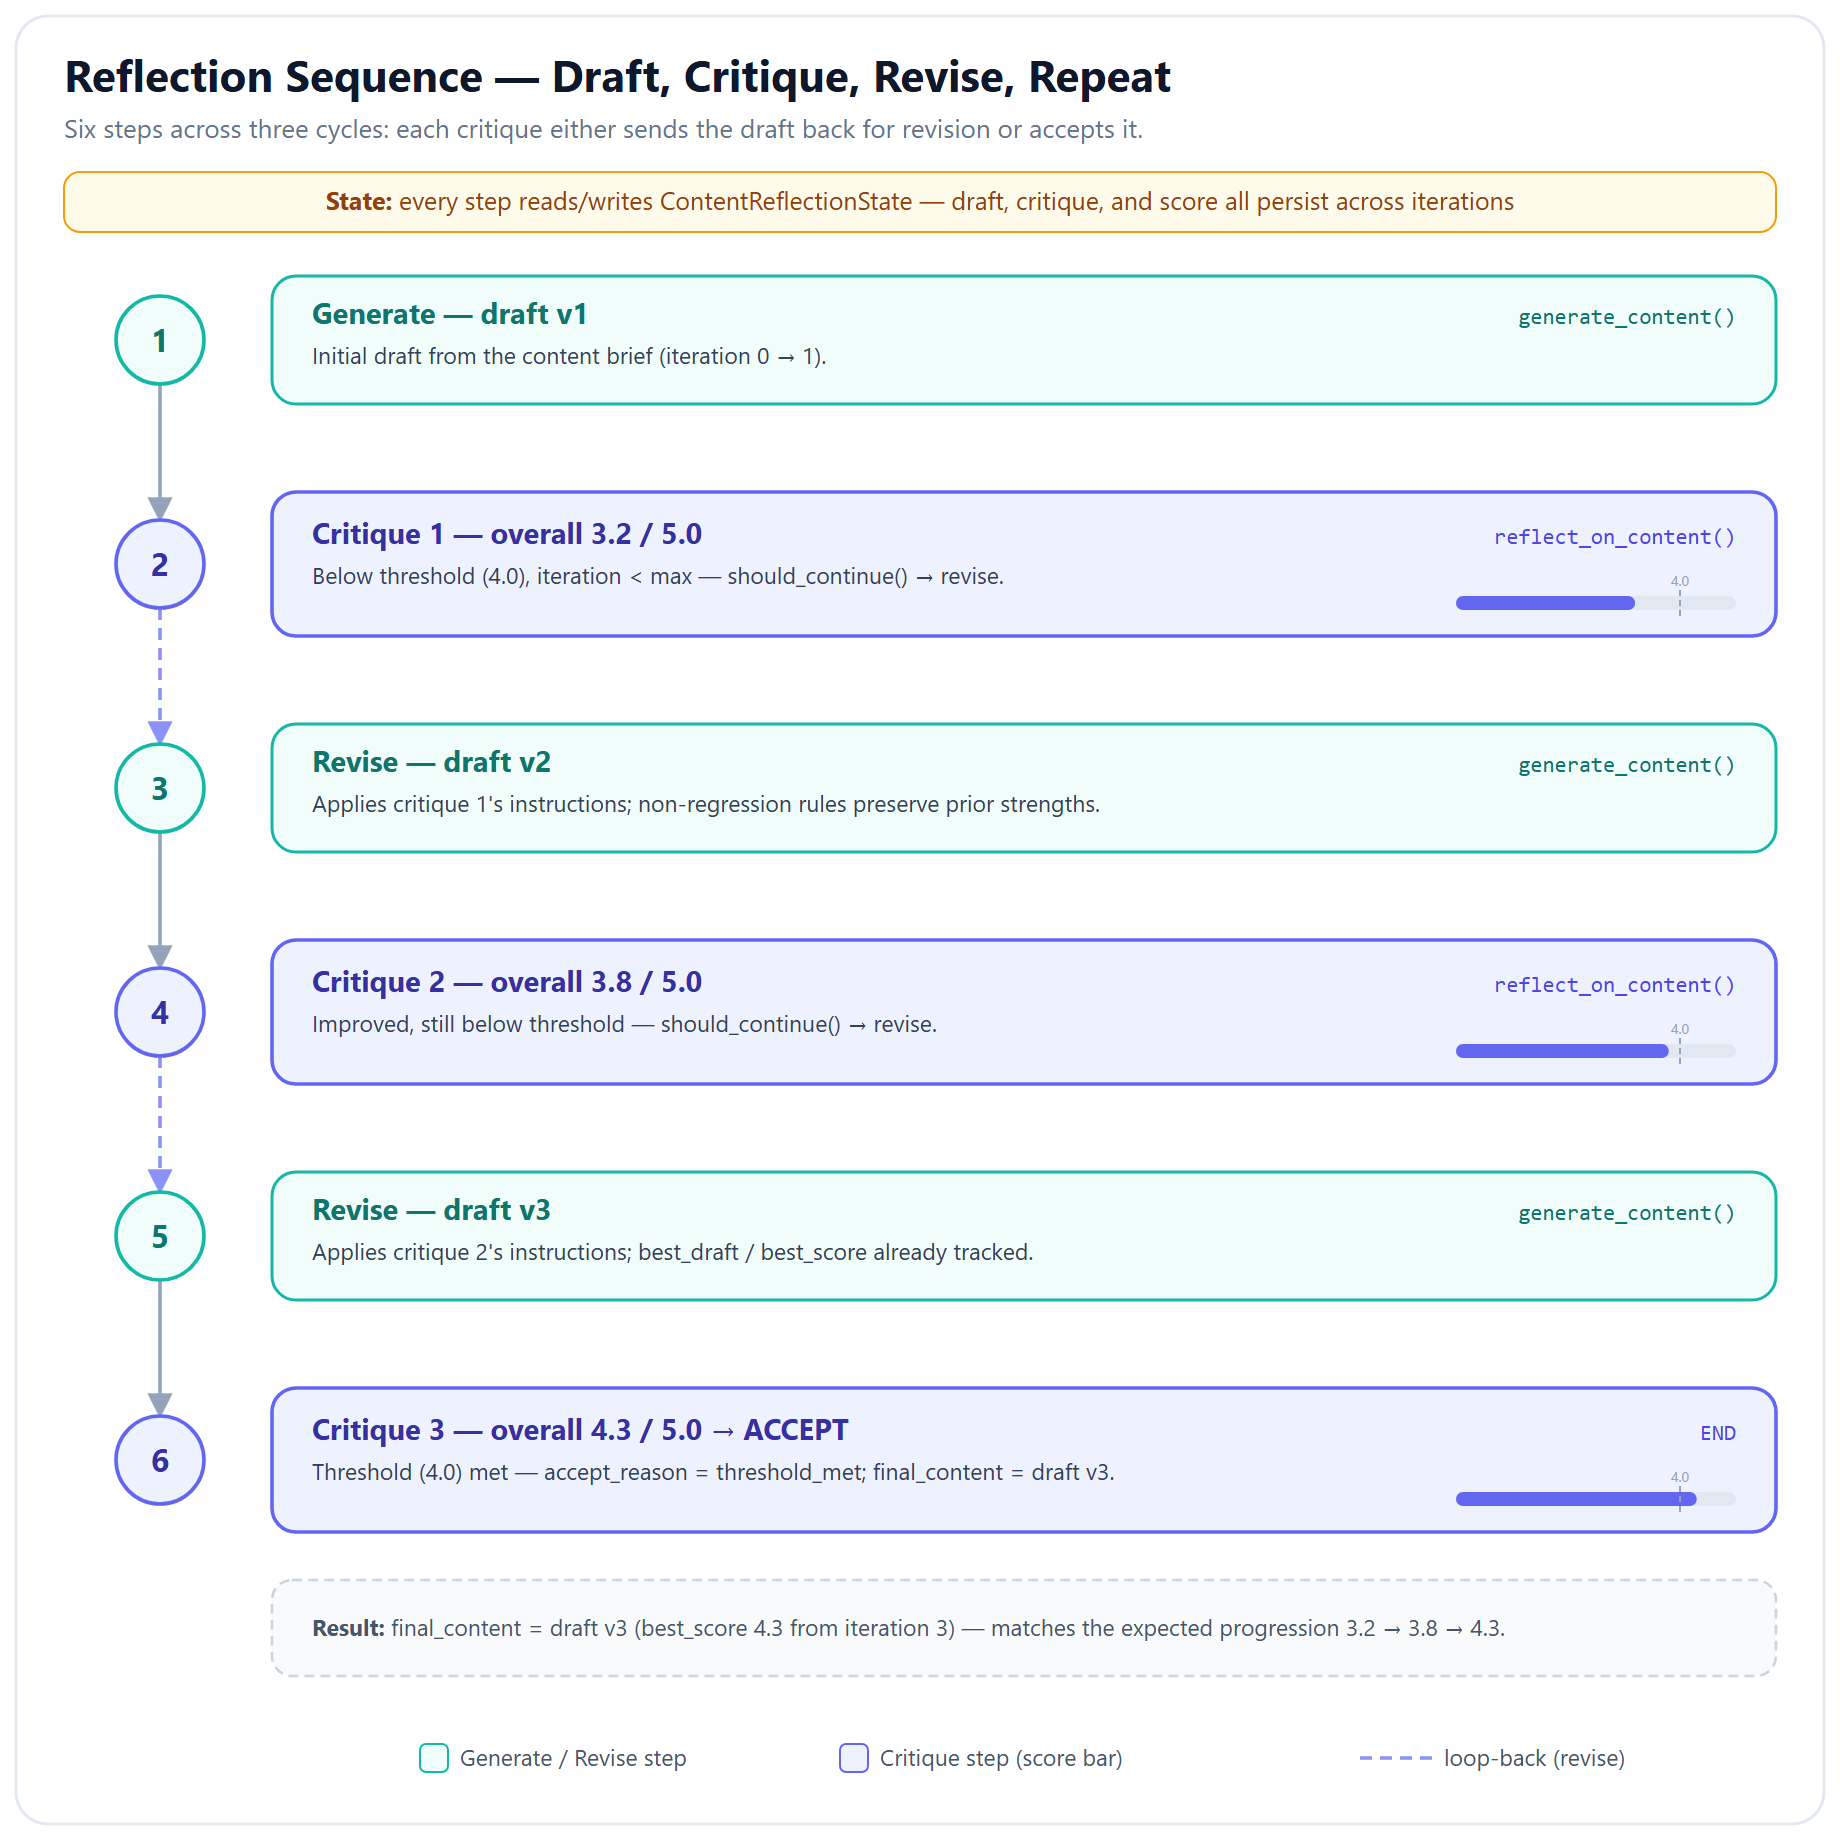

**Figure — Reflection sequence across three cycles.** Two full revision cycles carry the blended `overall_score` from 3.2 to 3.8 to 4.3 — the lab's expected progression — until the third critique clears the `quality_threshold` (4.0) and the loop accepts.

In [ ]:
# ============================================================
# Run the Reflection Pipeline (single execution)
# ============================================================

initial_state = {
    "content_brief": CONTENT_BRIEF,
    "brand_guidelines": BRAND_GUIDELINES,
    "current_draft": "",
    "critique": "",
    "specific_instructions": "",
    "dimension_scores": {},
    "hard_check_results": {},
    "llm_score": 0.0,
    "overall_score": 0.0,
    "best_draft": "",
    "best_score": 0.0,
    "best_iteration": 0,
    "revision_history": [],
    "iteration": 0,
    "max_iterations": 3,
    "quality_threshold": 4.0,
    "final_content": "",
    "accepted": False,
    "accept_reason": "",
}

print("Starting Reflection Pipeline (single execution)...")
print("=" * 70)
print(f"Quality Threshold: 4.0 / 5.0")
print(f"Max Iterations: 3")
print(f"Score blend: hard_checks {int(HARD_SCORE_WEIGHT*100)}% + LLM rubric {int(LLM_SCORE_WEIGHT*100)}%")
print("=" * 70)

# Accumulate state as the stream progresses
result = {}
for event in graph.stream(initial_state, stream_mode="updates"):
    for node_name, node_output in event.items():
        # Merge this node's output into result (handoff_log-style reducer for lists)
        for state_key, state_value in node_output.items():
            if state_key == "revision_history" and isinstance(state_value, list):
                result.setdefault(state_key, []).extend(state_value)
            else:
                result[state_key] = state_value

        print(f"\n--- node: {node_name} ---")

        if node_name == "generate":
            iteration = node_output.get("iteration", 0)
            draft = node_output.get("current_draft", "")
            print(f"  iteration {iteration}: generated {len(draft)} chars")
            print(f"  preview: {draft[:180]}...")

        elif node_name == "reflect":
            scores = node_output.get("dimension_scores", {})
            overall = node_output.get("overall_score", 0)
            llm_score = node_output.get("llm_score", 0)
            hard_check_results = node_output.get("hard_check_results", {})
            hard_score = hard_check_results.get("hard_score", 0) if hard_check_results else 0
            print(f"  hard_score: {hard_score:.2f}/1.00 "
                  f"({hard_check_results.get('word_count', 0)} words, "
                  f"FK={hard_check_results.get('flesch_kincaid_grade', 0)}, "
                  f"disclaimers={'OK' if hard_check_results.get('disclaimers_ok') else 'MISSING'}, "
                  f"forbidden={'OK' if hard_check_results.get('forbidden_ok') else 'FOUND'})")
            print(f"  LLM dimension scores:")
            for dimension_name, dimension_score in scores.items():
                print(f"    {dimension_name:<20s}: {dimension_score:.1f}/5.0")
            print(f"  llm_score:     {llm_score:.2f}/5.00")
            print(f"  OVERALL:       {overall:.2f}/5.00", end="")
            if "best_score" in node_output:
                print(f"  <-- NEW BEST (was tracking {result.get('best_score', 0):.2f})")
            else:
                print(f"  (best remains {result.get('best_score', 0):.2f} from iter "
                      f"{result.get('best_iteration', '?')})")

        elif node_name == "accept":
            print(f"  accept_reason: {node_output.get('accept_reason', '?')}")

print("\n" + "=" * 70)
print("PIPELINE COMPLETE")
print("=" * 70)
print(f"Total iterations run:   {result.get('iteration', 0)}")
print(f"Best score achieved:    {result.get('best_score', 0):.2f}  (at iteration {result.get('best_iteration', 0)})")
print(f"Accept reason:          {result.get('accept_reason', '?')}")
print(f"Final content length:   {len(result.get('final_content', ''))} characters")
print(f"Final draft is from:    iteration {result.get('best_iteration', 0)} (the best seen, not the latest)")


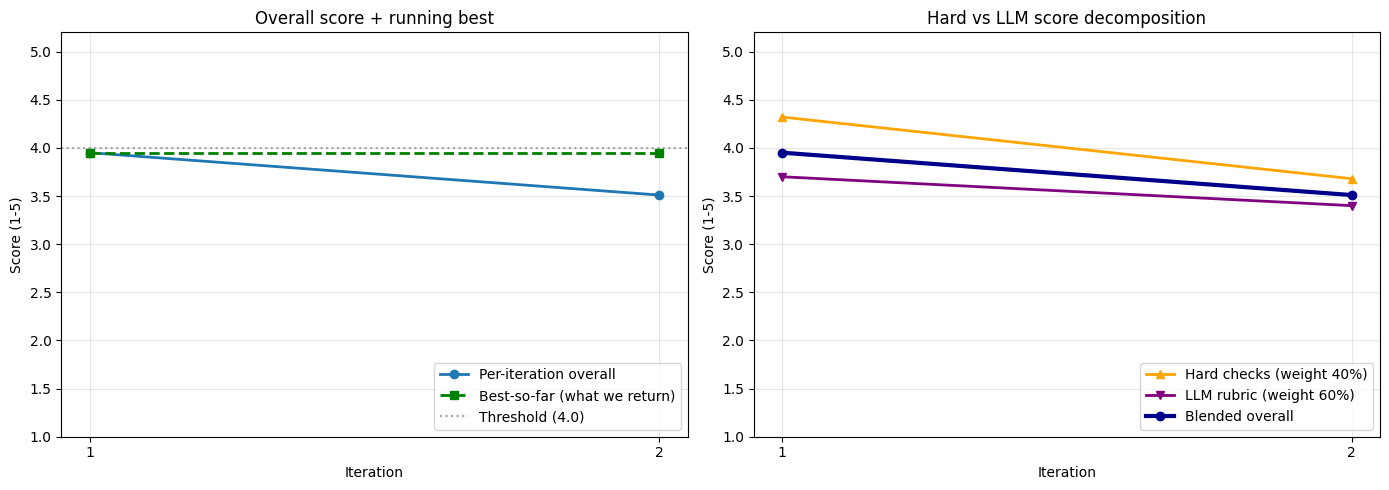

In [ ]:
# ============================================================
# Cell 22: Quality Convergence Visualization
# ============================================================
# Plots both the per-iteration score AND a running best line. The gap between
# them tells you whether the best-so-far safeguard earned its keep on this run.

history = result.get("revision_history", [])

if not history:
    print("No revision history available.")
else:
    # --- Text table ---
    print("QUALITY CONVERGENCE TABLE")
    print("=" * 90)
    header = f"{'Iter':>4} | {'hard/1.0':>8} | {'LLM/5.0':>8} | {'overall':>8} | {'running_best':>12} | flag"
    print(header)
    print("-" * 90)

    running_best = 0.0
    running_best_iteration = 0
    for entry in history:
        iteration_number = entry["iteration"]
        hard_score_fraction = entry["hard_score_1to5"] / 5.0  # back to 0-1 for display
        llm_score = entry["llm_score"]
        overall = entry["overall_score"]
        flag = ""
        if overall > running_best:
            running_best = overall
            running_best_iteration = iteration_number
            flag = "<-- new best"
        elif overall < running_best:
            flag = "<-- REGRESSED (best tracker saved us)"
        print(f"{iteration_number:>4} | {hard_score_fraction:>8.2f} | {llm_score:>8.2f} | {overall:>8.2f} | "
              f"{running_best:>8.2f} (iter {running_best_iteration}) | {flag}")
    print("=" * 90)
    print(f"\nFinal accepted draft: iteration {result.get('best_iteration', 0)} "
          f"with score {result.get('best_score', 0):.2f}")
    print(f"Accept reason: {result.get('accept_reason', '?')}")

    # --- Matplotlib chart ---
    try:
        import matplotlib.pyplot as plt

        figure, (overall_axis, decomposition_axis) = plt.subplots(1, 2, figsize=(14, 5))

        iterations = [entry["iteration"] for entry in history]
        overall_scores = [entry["overall_score"] for entry in history]
        hard_scores = [entry["hard_score_1to5"] for entry in history]
        llm_scores = [entry["llm_score"] for entry in history]

        # Running best line
        best_so_far = []
        highest_score_so_far = 0
        for score in overall_scores:
            highest_score_so_far = max(highest_score_so_far, score)
            best_so_far.append(highest_score_so_far)

        # Left: overall + running-best
        overall_axis.plot(iterations, overall_scores, marker="o", linewidth=2,
                          label="Per-iteration overall")
        overall_axis.plot(iterations, best_so_far, marker="s", linewidth=2, linestyle="--",
                          color="green", label="Best-so-far (what we return)")
        overall_axis.axhline(y=4.0, color="gray", linestyle=":", alpha=0.7,
                             label="Threshold (4.0)")
        overall_axis.set_xlabel("Iteration")
        overall_axis.set_ylabel("Score (1-5)")
        overall_axis.set_title("Overall score + running best")
        overall_axis.set_ylim(1, 5.2)
        overall_axis.set_xticks(iterations)
        overall_axis.legend(loc="lower right")
        overall_axis.grid(True, alpha=0.3)

        # Right: hard vs LLM decomposition
        decomposition_axis.plot(iterations, hard_scores, marker="^", linewidth=2,
                                color="orange",
                                label=f"Hard checks (weight {int(HARD_SCORE_WEIGHT*100)}%)")
        decomposition_axis.plot(iterations, llm_scores, marker="v", linewidth=2,
                                color="purple",
                                label=f"LLM rubric (weight {int(LLM_SCORE_WEIGHT*100)}%)")
        decomposition_axis.plot(iterations, overall_scores, marker="o", linewidth=3,
                                color="darkblue", label="Blended overall")
        decomposition_axis.set_xlabel("Iteration")
        decomposition_axis.set_ylabel("Score (1-5)")
        decomposition_axis.set_title("Hard vs LLM score decomposition")
        decomposition_axis.set_ylim(1, 5.2)
        decomposition_axis.set_xticks(iterations)
        decomposition_axis.legend(loc="lower right")
        decomposition_axis.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()
    except ImportError:
        print("(matplotlib not available)")


---

## Comparison: Single-Shot vs Reflection (proper N-trial comparison)

To quantify the value of the Reflection pattern honestly, we run **N=3 trials** of each approach and report mean ± standard deviation. This is much more reliable than an n=1 vs n=1 snapshot, because we have measured the critic's scoring variance on the same draft to be roughly ±0.10-0.20.

With n=1 comparisons a "7% improvement" might just be critic noise. With N=3 each we can see whether Reflection's improvement is larger than the natural variance.

**Cost warning:** this cell runs **6 full pipelines** (3 single-shot + 3 reflection, each reflection up to 3 iterations). Expect ~30 LLM calls and 1-2 minutes of runtime. This is deliberate — the proper comparison is the lab's main honest-evidence cell.

### What to expect (and why the finding is the lesson)

You might see Reflection come out slightly behind, slightly ahead, or statistically indistinguishable from single-shot. **All three outcomes are valid findings**, and for this specific task (marketing copy with a well-tuned generator prompt), slightly-behind or statistically-indistinguishable is the most likely result. That is not a failure of the lab — it is the point:

- The single-shot generator is already strong. GPT-4.1-mini with a detailed prompt produces drafts that hit 3.8-4.0 on the first try.
- Reflection's overhead (critic call + revision call per iteration) does not pay off when the baseline is close to the scoring ceiling.
- LLM critics have real scoring noise. Any delta smaller than ~0.2 is probably noise, not signal.

The mature engineering takeaway is: **you run this cell to find out whether Reflection earns its 3x cost on *your* task**, not to prove it always does. Reflection shines when (a) the task is harder (longer, more complex content), (b) the baseline is weaker (smaller generator, thinner prompt), or (c) the critic can actually detect improvements (hybrid validation helps here). For this lab's specific setup, an INCONCLUSIVE verdict is itself the honest answer. If you want Reflection to clearly win on a different task, the N-trial comparison is how you'd prove it.


In [ ]:
# ============================================================
# Cell 23: Single-Shot vs Reflection -- N-trial comparison
# ============================================================
# Runs 3 trials of each approach so we can report mean +/- std rather than
# a single-point comparison that would fall within critic noise.

import statistics

N_TRIALS = 10

def evaluate_draft(draft: str) -> dict:
    """Run hard_checks + LLM critic on a draft and return the blended score."""
    hard_check_results = run_hard_checks(draft)
    hard_score_1to5 = 1.0 + hard_check_results["hard_score"] * 4.0

    rubric_text = ""
    for dimension_name, dimension_info in LLM_RUBRIC.items():
        rubric_text += (f"\n- {dimension_name} (weight {dimension_info['weight']:.0%}): "
                        f"{dimension_info['description']}")

    prompt = f"""Evaluate this blog post on the 3 judgment-based dimensions below.
Deterministic checks are handled separately - do not re-score compliance/formatting.

CONTENT:
{draft}

RUBRIC:
{rubric_text}

Every dimension MUST have one of the exact names: brand_alignment, engagement, seo_quality"""
    critique: ContentCritique = critic_structured.invoke(prompt)
    scores = {dimension_score.dimension: dimension_score.score
              for dimension_score in critique.scores}
    llm_score = sum(scores.get(dimension_name, 3.0) * dimension_info["weight"]
                    for dimension_name, dimension_info in LLM_RUBRIC.items())
    overall = hard_score_1to5 * HARD_SCORE_WEIGHT + llm_score * LLM_SCORE_WEIGHT

    return {
        "hard_score_1to5": round(hard_score_1to5, 2),
        "llm_score": round(llm_score, 2),
        "overall": round(overall, 2),
        "dimension_scores": scores,
        "hard_passing": sum([hard_check_results["forbidden_ok"],
                             hard_check_results["disclaimers_ok"],
                             hard_check_results["word_count_ok"],
                             hard_check_results["fk_ok"],
                             hard_check_results["subheadings_ok"],
                             hard_check_results["bullets_ok"]]),
    }


def run_single_shot() -> dict:
    """Generate once, evaluate once. No revision."""
    prompt = f"""Write a marketing blog post based on this content brief:
{CONTENT_BRIEF}

Brand guidelines:
{BRAND_GUIDELINES}

Requirements: 700-900 words, include disclaimers (SEBI reg INA000012345, market risk,
past performance), avoid forbidden phrases, 3+ subheadings, 1+ bullet list, CTA."""
    draft = llm_generator.invoke([
        SystemMessage(content=GENERATOR_SYSTEM_PROMPT),
        HumanMessage(content=prompt),
    ]).content
    return evaluate_draft(draft)


def run_reflection() -> dict:
    """Run the full Reflection pipeline and return the best-seen scores."""
    result = graph.invoke({
        "content_brief": CONTENT_BRIEF, "brand_guidelines": BRAND_GUIDELINES,
        "current_draft": "", "critique": "", "specific_instructions": "",
        "dimension_scores": {}, "hard_check_results": {},
        "llm_score": 0.0, "overall_score": 0.0,
        "best_draft": "", "best_score": 0.0, "best_iteration": 0,
        "revision_history": [],
        "iteration": 0, "max_iterations": 3, "quality_threshold": 4.0,
        "final_content": "", "accepted": False, "accept_reason": "",
    })
    # The reflection pipeline already evaluated the best draft during the run
    # so we report its stored best_score rather than re-evaluating (saves cost).
    return {
        "overall": result["best_score"],
        "iterations": result["iteration"],
        "best_iteration": result["best_iteration"],
        "accept_reason": result["accept_reason"],
    }


print(f"Running {N_TRIALS} trials of each approach (~30 LLM calls total)...")
print("=" * 70)

# --- Run N single-shot trials ---
print("\nSingle-shot trials:")
single_shot_scores = []
for trial_index in range(N_TRIALS):
    trial_result = run_single_shot()
    single_shot_scores.append(trial_result["overall"])
    print(f"  Trial {trial_index+1}: overall={trial_result['overall']:.2f}  "
          f"(hard={trial_result['hard_score_1to5']:.2f}, "
          f"LLM={trial_result['llm_score']:.2f}, "
          f"hard_passing={trial_result['hard_passing']}/6)")

# --- Run N reflection trials ---
print("\nReflection trials:")
reflection_scores = []
reflection_iteration_counts = []
for trial_index in range(N_TRIALS):
    trial_result = run_reflection()
    reflection_scores.append(trial_result["overall"])
    reflection_iteration_counts.append(trial_result["iterations"])
    print(f"  Trial {trial_index+1}: best={trial_result['overall']:.2f} "
          f"at iter {trial_result['best_iteration']} "
          f"(ran {trial_result['iterations']} iters, "
          f"reason={trial_result['accept_reason']})")

# --- Report statistics ---
single_shot_mean = statistics.mean(single_shot_scores)
single_shot_stdev = (statistics.stdev(single_shot_scores)
                     if len(single_shot_scores) > 1 else 0.0)
reflection_mean = statistics.mean(reflection_scores)
reflection_stdev = (statistics.stdev(reflection_scores)
                    if len(reflection_scores) > 1 else 0.0)
delta = reflection_mean - single_shot_mean
percent_improvement = (delta / single_shot_mean) * 100 if single_shot_mean > 0 else 0.0

print("\n" + "=" * 70)
print(f"STATISTICAL SUMMARY (N={N_TRIALS} trials each)")
print("=" * 70)
print(f"  Single-shot:  mean={single_shot_mean:.2f}  std={single_shot_stdev:.2f}  "
      f"scores={single_shot_scores}")
print(f"  Reflection:   mean={reflection_mean:.2f}  std={reflection_stdev:.2f}  "
      f"scores={reflection_scores}")
print("  Avg iterations used by reflection: "
      f"{statistics.mean(reflection_iteration_counts):.1f}")
print()
print(f"  Absolute improvement: {delta:+.2f}")
print(f"  Relative improvement: {percent_improvement:+.1f}%")
print()

# --- Honest interpretation ---
combined_stdev = (single_shot_stdev + reflection_stdev) / 2
if abs(delta) < combined_stdev:
    verdict = ("INCONCLUSIVE: improvement is within natural critic variance. "
               "Need more trials (N>=10) to draw confident conclusions.")
elif delta > combined_stdev:
    verdict = ("MEANINGFUL: improvement exceeds critic variance. "
               "Reflection appears to help on this task.")
else:
    verdict = "Reflection did not help on this comparison."

print(f"  Verdict: {verdict}")
print()
print("  Cost note: Reflection used ~2-3x more LLM calls per trial than single-shot.")
print("  Latency note: Reflection is ~3-4x slower per piece of content.")
print("  When comparing, consider whether the quality delta is worth the cost.")


In [ ]:
# --- Display the Final Accepted Content ---

# ============================================================
# Display the final accepted content
# ============================================================

from IPython.display import Markdown, display

print(f"Final Score: {result['overall_score']:.2f}/5.0")
print(f"Iterations: {result['iteration']}")
print(f"Accepted: {result['accepted']}")
print("\n" + "=" * 60)
print("FINAL ACCEPTED CONTENT")
print("=" * 60 + "\n")

display(Markdown(result.get("final_content", "No content produced.")))

---

## BONUS: Functional API Version (with the same production safeguards)

The same Reflection loop can be expressed using LangGraph's `@entrypoint` / `@task` decorators — a plain Python while-loop instead of a cyclic graph. This version has the same behavior as the graph version but is often easier to debug because the control flow is sequential Python.

We port over **all the safeguards** from the graph version:
- `run_hard_checks()` runs every iteration
- Blended score (40% hard + 60% LLM)
- Best-so-far tracking (return best, not latest)
- Early-stop on no improvement
- `accept_reason` recorded for audit

The one thing lost versus the graph version: LangGraph's visual graph diagram and streaming observability. For production use, pick graph when you want a visual architecture and streaming; pick functional when you want straight-line Python and local-variable debugging.


In [ ]:
# ============================================================
# Cell 24: BONUS -- Functional API Version (with production safeguards)
# ============================================================

from langgraph.func import entrypoint, task


@task
def generate_initial_task(brief: str, guidelines: str) -> str:
    """Generate initial content from the brief."""
    prompt = f"""Write a marketing blog post based on this content brief:
{brief}

Brand guidelines:
{guidelines}

Requirements: 700-900 words. Include disclaimers VERBATIM (SEBI reg INA000012345,
market risk, past performance). Avoid forbidden phrases (guaranteed returns,
risk-free, beat the market, get rich quick). 3+ subheadings, 1+ bullet list, clear CTA."""
    result = llm_generator.invoke([
        SystemMessage(content=GENERATOR_SYSTEM_PROMPT),
        HumanMessage(content=prompt),
    ])
    return result.content


@task
def evaluate_draft_task(draft: str, guidelines: str) -> dict:
    """Hybrid evaluation: hard checks + LLM critic, blended score."""
    hard_check_results = run_hard_checks(draft)
    hard_score_1to5 = 1.0 + hard_check_results["hard_score"] * 4.0
    hard_report = format_hard_check_report(hard_check_results)

    rubric_text = ""
    for dimension_name, dimension_info in LLM_RUBRIC.items():
        rubric_text += (f"\n- {dimension_name} (weight {dimension_info['weight']:.0%}): "
                        f"{dimension_info['description']}")

    prompt = f"""Evaluate on ONLY the 3 judgment dimensions below. Deterministic checks
have already been run - do not re-score compliance/formatting.

CONTENT:
{draft}

DETERMINISTIC CHECKS (already run):
{hard_report}

RUBRIC:
{rubric_text}

BRAND GUIDELINES:
{guidelines}

Every dimension MUST have one of the exact names: brand_alignment, engagement, seo_quality.
Give revision instructions only for dimensions scored below 4.0. Do not ask the writer to
fix items the hard checks already handle."""
    critique: ContentCritique = critic_structured.invoke(prompt)

    scores = {dimension_score.dimension: dimension_score.score
              for dimension_score in critique.scores}
    llm_score = sum(scores.get(dimension_name, 3.0) * dimension_info["weight"]
                    for dimension_name, dimension_info in LLM_RUBRIC.items())
    overall = hard_score_1to5 * HARD_SCORE_WEIGHT + llm_score * LLM_SCORE_WEIGHT

    return {
        "scores": scores,
        "hard_score_1to5": round(hard_score_1to5, 2),
        "llm_score": round(llm_score, 2),
        "overall": round(overall, 2),
        "hard_check_results": hard_check_results,
        "instructions": critique.specific_revision_instructions,
        "assessment": critique.overall_assessment,
        "top_strength": critique.top_strength,
    }


@task
def revise_draft_task(draft: str, instructions: str, top_strength: str, guidelines: str) -> str:
    """Revise with explicit non-regression instructions."""
    prompt = f"""Revise this blog post based on the editor's feedback.

CURRENT DRAFT:
{draft}

REVISION INSTRUCTIONS:
{instructions}

PREVIOUSLY PRAISED (do NOT undo this):
{top_strength}

NON-REGRESSION RULES:
- Do not remove required disclaimers (SEBI, market risk, past performance).
- Do not introduce forbidden phrases.
- Keep 700-900 words and existing structural elements.

BRAND GUIDELINES:
{guidelines}

Write the revised draft now."""
    return llm_generator.invoke([
        SystemMessage(content=GENERATOR_SYSTEM_PROMPT),
        HumanMessage(content=prompt),
    ]).content


@entrypoint()
def reflection_pipeline_functional(inputs: dict) -> dict:
    """Reflection pipeline using the Functional API with all production safeguards:
       hard_checks, best-so-far tracking, early-stop on no improvement.
    """
    brief = inputs["brief"]
    guidelines = inputs["guidelines"]
    threshold = inputs.get("threshold", 4.0)
    max_iterations = inputs.get("max_iterations", 3)

    # Step 1: initial generation + evaluation
    draft = generate_initial_task(brief, guidelines).result()
    evaluation = evaluate_draft_task(draft, guidelines).result()
    history = [{"iteration": 1, **evaluation, "draft_len": len(draft)}]

    best_draft = draft
    best_score = evaluation["overall"]
    best_iteration = 1
    accept_reason = None

    # Step 2: reflection loop
    for iteration_number in range(2, max_iterations + 1):
        # Threshold check on the latest draft
        if evaluation["overall"] >= threshold:
            accept_reason = "threshold_met"
            break

        # Revise
        draft = revise_draft_task(draft, evaluation["instructions"],
                                  evaluation["top_strength"], guidelines).result()
        evaluation = evaluate_draft_task(draft, guidelines).result()
        history.append({"iteration": iteration_number, **evaluation,
                        "draft_len": len(draft)})

        # Update best-so-far
        if evaluation["overall"] > best_score:
            best_draft = draft
            best_score = evaluation["overall"]
            best_iteration = iteration_number
        else:
            # Early-stop on no improvement
            accept_reason = "no_improvement"
            break

    # If we ran the full loop, check one more time whether the last iteration passed
    if accept_reason is None:
        if evaluation["overall"] >= threshold:
            accept_reason = "threshold_met"
        else:
            accept_reason = "max_iterations"

    return {
        "final_content": best_draft,   # best seen, not latest
        "best_score": best_score,
        "best_iteration": best_iteration,
        "history": history,
        "iterations_run": len(history),
        "accept_reason": accept_reason,
    }


print("Functional API version defined (with production safeguards).")
print("  - Same hybrid validation (hard_checks + LLM critic, 40/60 blend)")
print("  - Best-so-far tracking (returns best_draft, not latest)")
print("  - Early-stop on no improvement")
print("  - accept_reason recorded for audit")
print()

# ============================================================================
# Run the Functional API version
# ============================================================================
print("Running Functional API version...")
print("=" * 60)

func_result = reflection_pipeline_functional.invoke({
    "brief": CONTENT_BRIEF,
    "guidelines": BRAND_GUIDELINES,
    "threshold": 4.0,
    "max_iterations": 3,
})

print(f"\nFunctional API results:")
print(f"  iterations run:   {func_result['iterations_run']}")
print(f"  best score:       {func_result['best_score']:.2f} (at iteration {func_result['best_iteration']})")
print(f"  accept reason:    {func_result['accept_reason']}")
print(f"  content length:   {len(func_result['final_content'])} characters")

print(f"\n  Score progression:")
running_best = 0
for entry in func_result["history"]:
    marker = ""
    if entry["overall"] > running_best:
        running_best = entry["overall"]
        marker = " <-- new best"
    elif entry["overall"] < running_best:
        marker = " <-- regressed (best tracker saved us)"
    print(f"    Iteration {entry['iteration']}: "
          f"hard={entry['hard_score_1to5']:.2f}, LLM={entry['llm_score']:.2f}, "
          f"overall={entry['overall']:.2f}{marker}")


---

## Conclusion: Key Takeaways

### What We Built

| Topic | What We Built |
|-------|--------------|
| Reflection pattern | Cyclic graph: generate -> reflect -> (revise | accept) |
| Hybrid validation | Deterministic hard_checks (40%) + LLM judgment (60%) |
| Best-so-far tracking | Returns `best_draft` across iterations, never a regressed version |
| Early-stop gate | Halts when current score does not beat best (saves compute + ships best) |
| Audit trail | `revision_history` via `operator.add` + `accept_reason` on final state |
| Functional API port | Same pattern, same safeguards, straight-line Python control flow |
| Honest comparison | N=3 trials of single-shot vs Reflection with mean +/- std |

### Key Takeaways

1. **The Reflection pattern is a mechanism, not a silver bullet.** It produces a cyclic LangGraph that works correctly. Whether it *improves quality* depends on critic consistency, prompt design, and the safeguards around it.
2. **LLM critics are not calibrated judges.** The same critic on the same draft will give different scores across runs. We measured roughly ±0.10-0.20 variance on the overall weighted score. That is why hard_checks carry 40% of the total — regex and `textstat` do not drift.
3. **Hybrid validation is the real win.** Binary facts (disclaimer present? forbidden phrase absent? FK grade 8-10?) are best answered by Python. Reserve the LLM for things only a human editor can judge: tone, hook, flow.
4. **Best-so-far + early-stop is mandatory in production.** Without them, a naive Reflection loop can regress between iterations and ship the worse draft. The notebook's convergence table explicitly flags any regression with "best tracker saved us" so you can see when the safeguard earned its keep.
5. **Compare properly or do not compare.** An n=1 single-shot vs n=1 Reflection comparison is not evidence of anything when the signal (quality delta) is smaller than the noise (critic variance). N=3 is the minimum; N=10+ is better.
6. **Reflection has real costs.** ~3x more LLM calls, ~3-4x more latency than single-shot. Use it when quality matters more than speed and when you have evidence the delta is real.

### Known Limitations (Honest Assessment)

Some issues in Reflection are inherent to the approach and cannot be fully fixed:

- **Critic non-determinism.** `gpt-5-mini` is a reasoning model with no temperature setting; the same prompt returns different scores across runs. Partial fix: ensemble multiple critic calls and average; full fix requires a deterministic evaluator. Hard_checks give us 40% deterministic signal as compensation.
- **Critic anchored-low priors.** We instruct the critic that "first drafts typically score 2.5-3.5" which pushes it toward conservative scoring. This means crossing the 4.0 threshold is hard even for good drafts. Alternatives: calibrate the critic against gold-standard examples, or lower the threshold to reflect the critic's actual scoring distribution.
- **Goalpost-moving.** Iteration N+1's critic may find new things to complain about while the generator undoes previous good edits. We mitigate with explicit "do not undo top_strength" in the revision prompt, and hard-kill via early-stop when no improvement is detected. We do not eliminate it.
- **Hard_check coverage is not total.** `textstat` approximates Flesch-Kincaid; subheading detection by regex misses some valid structures; "required disclaimer present" does not verify it is in the right place in the document. The hard_check layer raises the floor but does not replace human editorial review.
- **No human-in-the-loop (HITL).** When the pipeline accepts with reason `max_iterations` (the threshold wasn't met), we ship the best-effort draft silently. Production would route `max_iterations` accepts to a human reviewer with the full critique trail.

### Extensions to Try (each is a weekend-scale upgrade worth real points on a project portfolio)

1. **Ensemble the critic**: call the critic N=3 times per evaluation and average the scores. Reduces variance at 3x the critic cost.
2. **Add HITL escalation**: when `accept_reason == "max_iterations"`, emit a LangGraph `interrupt()` with the full history for a human editor. This is the Lab 3.2 HITL pattern applied to content quality.
3. **Calibrate the critic against a gold set**: collect 10 human-labeled drafts with known scores, run the critic against them, measure correlation. Use the calibration to adjust the threshold or re-weight dimensions.
4. **Expand hard_checks**: Cloze test for keyword coverage, TF-IDF check for keyword stuffing, heading-hierarchy validation, CTA positioning.
5. **Cost instrumentation**: log token counts per iteration and report cost-per-quality-point. Does a +0.3 quality uplift justify 3x the cost in your use case?
6. **Diversity-preserving revision**: tell the generator to try two distinct revision approaches per iteration and pick the one the critic scores higher. Reduces mode collapse.
7. **Cross-critic validation**: use `gpt-5-mini` and `claude-sonnet-4-5` as independent critics; only accept drafts both rate above threshold. Reduces single-critic blind spots at ~2x cost.

### Reflection Pattern -- When to Use It

| Use Reflection When | Do NOT Use Reflection When |
|---------------------|----------------------------|
| Content quality matters (marketing, reports) | Output has a single correct answer |
| You have deterministic checks for the objective parts | Binary pass/fail validation is the whole job (use Evaluator-Optimizer instead) |
| Multiple quality dimensions to optimize | Speed matters more than quality |
| Creative output (writing, design briefs) | Simple factual lookups |
| Brand voice alignment needed | You lack the budget for 3x the LLM calls |
| You will run N-trial validation before production | You plan to ship from a single output evaluation |

### What is Next

- **Module 4** covers the OpenAI Agents SDK, realtime voice agents and CrewAI — expanding beyond LangGraph into the broader agentic AI ecosystem.
